# 01 — Exploratory Data Analysis (EDA)

**Overview** — the three raw files and where the combined dataset comes from.  
**5.1 Data exploration and preparation** — description, summary statistics, visualisation, missingness and outliers, invalid-PM2.5 removal, duplicates, correlations / VIF, PM2.5–predictor relationships, target distribution.  
**5.3 Preprocessing without data leakage** — missing values, scaling / feature selection, outliers.  
**Summary table** → `results/Exploratory_Data.csv`.

Run this notebook **before** `02_timeseries.ipynb` (it creates `data/processed/combined_clean.csv` and `results/Exploratory_Data.csv`).


## Overview of the raw files

In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Paths (notebooks/ -> ../data/raw, ../data/processed, ../results)
RAW_DIR = "../data/raw"
PROCESSED_DIR = "../data/processed"
RESULTS_DIR = "../results"

pm25 = pd.read_csv(f"{RAW_DIR}/pm25.csv")
gee = pd.read_csv(f"{RAW_DIR}/gee_features_daily.csv")
combined = pd.read_csv(f"{RAW_DIR}/combined_gee_pm25.csv")

In [ ]:
# Display the first five rows of each dataset

print("PM2.5 DATASET")
display(pm25.head(47))
print("GEE FEATURES DATASET")
display(gee.head(50))
print("COMBINED DATASET")
display(combined.head())

PM2.5 DATASET


,date,latitude,longitude,pm25,sensor_name
0,2016-11-21,38.788056,-0.697222,4.000000,ONTINYENT
1,2016-11-21,39.456111,-0.375833,3.000000,VALÈNCIA-PISTA DE SILLA
2,2016-11-21,39.480300,-0.336400,2.000000,VALÈNCIA-POLITÈCNIC
3,2016-11-21,39.481100,-0.408300,5.000000,VALÈNCIA - MOLÍ DEL SOL
4,2016-11-21,39.481111,-0.447222,2.000000,QUART DE POBLET
5,2016-11-21,39.634167,-0.265833,1.000000,SAGUNT CEA
6,2016-11-21,39.705278,-0.336667,1.000000,ALBALAT DELS TARONGERS
7,2016-11-21,39.782222,-0.359167,1.000000,ALGAR DE PALÀNCIA
8,2016-11-21,39.892222,-0.065000,3.000000,BURRIANA
9,2016-11-22,38.788056,-0.697222,1.000000,ONTINYENT


GEE FEATURES DATASET


,date,datetime_utc,id,lat,lon,temperature_celsius,pressure_mb,wind_u,wind_v,NO2,CO,O3,AOD
0,2016-11-21,2016-11-21 00:00:00,90,39.235833,9.115000,15.842538,994.344313,-2.613506,2.663921,NaN,NaN,NaN,0.207000
1,2016-11-21,2016-11-21 00:00:00,91,39.260556,9.136389,15.842538,994.344313,-2.613506,2.663921,NaN,NaN,NaN,0.207000
2,2016-11-22,2016-11-22 00:00:00,28,36.203880,-5.383710,13.119320,989.320581,1.555070,0.348089,NaN,NaN,NaN,0.277000
3,2016-11-22,2016-11-22 00:00:00,40,41.426100,2.148000,15.658871,997.975164,-1.073064,0.549383,NaN,NaN,NaN,0.197000
4,2016-11-22,2016-11-22 00:00:00,51,41.424066,2.185757,15.658871,997.975164,-1.073064,0.549383,NaN,NaN,NaN,0.197000
5,2016-11-22,2016-11-22 00:00:00,52,41.431949,2.180739,15.658871,997.975164,-1.073064,0.549383,NaN,NaN,NaN,0.197000
6,2016-11-22,2016-11-22 00:00:00,54,41.430123,2.179321,15.658871,997.975164,-1.073064,0.549383,NaN,NaN,NaN,0.197000
7,2016-11-22,2016-11-22 00:00:00,56,41.425535,2.186864,15.658871,997.975164,-1.073064,0.549383,NaN,NaN,NaN,0.197000
8,2016-11-22,2016-11-22 00:00:00,60,41.415910,2.187094,15.658871,997.975164,-1.073064,0.549383,NaN,NaN,NaN,0.197000
9,2016-11-22,2016-11-22 00:00:00,62,41.401828,2.166360,15.658871,997.975164,-1.073064,0.549383,NaN,NaN,NaN,0.197000


COMBINED DATASET


,date,datetime_utc,id,latitude,longitude,temperature_celsius,pressure_mb,wind_u,wind_v,NO2,CO,O3,AOD,pm25,sensor_name
0,2016-11-25,2016-11-25 00:00:00,1,38.788056,-0.697222,6.493180,946.288660,0.230240,0.735303,NaN,NaN,NaN,0.1110,2.750000,ONTINYENT
1,2016-11-25,2016-11-25 00:00:00,36,39.945278,-0.056389,9.251236,993.626994,0.783218,-0.592618,NaN,NaN,NaN,0.0220,11.666667,ALMASSORA-C. P. OCHANDO
2,2016-11-30,2016-11-30 00:00:00,35,40.051944,-0.189722,10.044782,981.911432,-2.211047,-1.568971,NaN,NaN,NaN,0.2380,2.400000,ALCORA
3,2016-11-30,2016-11-30 00:00:00,37,40.062222,0.072778,12.299584,1008.794766,-3.236886,-2.804465,NaN,NaN,NaN,0.2480,2.600000,BENICASSIM
4,2016-12-02,2016-12-02 00:00:00,1,38.788056,-0.697222,9.350630,953.114180,0.953454,0.293060,NaN,NaN,NaN,0.0755,2.750000,ONTINYENT


In [ ]:
datasets = {"PM2.5": pm25, "GEE": gee, "Combined": combined}

for name, df in datasets.items():
    print("\n==========", name, "==========")
    print("First 5 rows:")
    display(df.head())
    print("Dataset information:")
    df.info()


========== PM2.5 ==========
First 5 rows:


,date,latitude,longitude,pm25,sensor_name
0,2016-11-21,38.788056,-0.697222,4.0,ONTINYENT
1,2016-11-21,39.456111,-0.375833,3.0,VALÈNCIA-PISTA DE SILLA
2,2016-11-21,39.480300,-0.336400,2.0,VALÈNCIA-POLITÈCNIC
3,2016-11-21,39.481100,-0.408300,5.0,VALÈNCIA - MOLÍ DEL SOL
4,2016-11-21,39.481111,-0.447222,2.0,QUART DE POBLET


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 88041 entries, 0 to 88040
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         88041 non-null  str    
 1   latitude     88041 non-null  float64
 2   longitude    88041 non-null  float64
 3   pm25         88041 non-null  float64
 4   sensor_name  88041 non-null  str    
dtypes: float64(3), str(2)
memory usage: 3.4 MB

========== GEE ==========
First 5 rows:


,date,datetime_utc,id,lat,lon,temperature_celsius,pressure_mb,wind_u,wind_v,NO2,CO,O3,AOD
0,2016-11-21,2016-11-21 00:00:00,90,39.235833,9.115000,15.842538,994.344313,-2.613506,2.663921,NaN,NaN,NaN,0.207
1,2016-11-21,2016-11-21 00:00:00,91,39.260556,9.136389,15.842538,994.344313,-2.613506,2.663921,NaN,NaN,NaN,0.207
2,2016-11-22,2016-11-22 00:00:00,28,36.203880,-5.383710,13.119320,989.320581,1.555070,0.348089,NaN,NaN,NaN,0.277
3,2016-11-22,2016-11-22 00:00:00,40,41.426100,2.148000,15.658871,997.975164,-1.073064,0.549383,NaN,NaN,NaN,0.197
4,2016-11-22,2016-11-22 00:00:00,51,41.424066,2.185757,15.658871,997.975164,-1.073064,0.549383,NaN,NaN,NaN,0.197


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 164208 entries, 0 to 164207
Data columns (total 13 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   date                 164208 non-null  str    
 1   datetime_utc         164208 non-null  str    
 2   id                   164208 non-null  int64  
 3   lat                  164208 non-null  float64
 4   lon                  164208 non-null  float64
 5   temperature_celsius  164208 non-null  float64
 6   pressure_mb          164208 non-null  float64
 7   wind_u               164208 non-null  float64
 8   wind_v               164208 non-null  float64
 9   NO2                  144605 non-null  float64
 10  CO                   144605 non-null  float64
 11  O3                   144294 non-null  float64
 12  AOD                  164208 non-null  float64
dtypes: float64(10), int64(1), str(2)
memory usage: 16.3 MB

========== Combined ==========
First 5 rows:


,date,datetime_utc,id,latitude,longitude,temperature_celsius,pressure_mb,wind_u,wind_v,NO2,CO,O3,AOD,pm25,sensor_name
0,2016-11-25,2016-11-25 00:00:00,1,38.788056,-0.697222,6.493180,946.288660,0.230240,0.735303,NaN,NaN,NaN,0.1110,2.750000,ONTINYENT
1,2016-11-25,2016-11-25 00:00:00,36,39.945278,-0.056389,9.251236,993.626994,0.783218,-0.592618,NaN,NaN,NaN,0.0220,11.666667,ALMASSORA-C. P. OCHANDO
2,2016-11-30,2016-11-30 00:00:00,35,40.051944,-0.189722,10.044782,981.911432,-2.211047,-1.568971,NaN,NaN,NaN,0.2380,2.400000,ALCORA
3,2016-11-30,2016-11-30 00:00:00,37,40.062222,0.072778,12.299584,1008.794766,-3.236886,-2.804465,NaN,NaN,NaN,0.2480,2.600000,BENICASSIM
4,2016-12-02,2016-12-02 00:00:00,1,38.788056,-0.697222,9.350630,953.114180,0.953454,0.293060,NaN,NaN,NaN,0.0755,2.750000,ONTINYENT


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 41718 entries, 0 to 41717
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   date                 41718 non-null  str    
 1   datetime_utc         41718 non-null  str    
 2   id                   41718 non-null  int64  
 3   latitude             41718 non-null  float64
 4   longitude            41718 non-null  float64
 5   temperature_celsius  41718 non-null  float64
 6   pressure_mb          41718 non-null  float64
 7   wind_u               41718 non-null  float64
 8   wind_v               41718 non-null  float64
 9   NO2                  39308 non-null  float64
 10  CO                   39308 non-null  float64
 11  O3                   39267 non-null  float64
 12  AOD                  41718 non-null  float64
 13  pm25                 41718 non-null  float64
 14  sensor_name          41718 non-null  str    
dtypes: float64(11), int64(1), 

In [ ]:
# Geographic coverage of PM2.5 dataset
print("PM2.5 DATASET")
print("Latitude:", pm25["latitude"].min(), "to", pm25["latitude"].max())
print("Longitude:", pm25["longitude"].min(), "to", pm25["longitude"].max())


# Geographic coverage of GEE dataset
print("\nGEE DATASET")
print("Latitude:", gee["lat"].min(), "to", gee["lat"].max())
print("Longitude:", gee["lon"].min(), "to", gee["lon"].max())


# Geographic coverage of Combined dataset
print("\nCOMBINED DATASET")
print("Latitude:", combined["latitude"].min(), "to", combined["latitude"].max())
print("Longitude:", combined["longitude"].min(), "to", combined["longitude"].max())

# Number of unique monitoring locations

print("\nPM2.5 DATASET")
print("Unique stations:", pm25["sensor_name"].nunique())
print(
    "Unique coordinate pairs:",
    pm25[["latitude", "longitude"]].drop_duplicates().shape[0],
)


print("\nGEE DATASET")
print("Unique location IDs:", gee["id"].nunique())
print("Unique coordinate pairs:", gee[["lat", "lon"]].drop_duplicates().shape[0])


print("\nCOMBINED DATASET")
print("Unique location IDs:", combined["id"].nunique())
print("Unique stations:", combined["sensor_name"].nunique())
print(
    "Unique coordinate pairs:",
    combined[["latitude", "longitude"]].drop_duplicates().shape[0],
)

PM2.5 DATASET
Latitude: 34.29039 to 43.68928999986467
Longitude: -5.663499999930786 to 9.446417000351037

GEE DATASET
Latitude: 36.13331699932336 to 43.5302972250095
Longitude: -5.663499999930786 to 9.136389000276088

COMBINED DATASET
Latitude: 36.13331699932336 to 43.5302972250095
Longitude: -5.663499999930786 to 9.136389000276088
PM2.5 DATASET
Unique stations: 125
Unique coordinate pairs: 133

GEE DATASET
Unique location IDs: 100
Unique coordinate pairs: 100

COMBINED DATASET
Unique location IDs: 98
Unique stations: 94
Unique coordinate pairs: 98


In [ ]:
# PM2.5 dataset
print("PM2.5 DATASET")
display(
    pd.DataFrame(
        {
            "Missing Values": pm25.isnull().sum(),
            "Percentage (%)": pm25.isnull().mean() * 100,
        }
    )
)
# GEE dataset
print("\nGEE DATASET")
display(
    pd.DataFrame(
        {
            "Missing Values": gee.isnull().sum(),
            "Percentage (%)": gee.isnull().mean() * 100,
        }
    )
)
# Combined dataset
print("\nCOMBINED DATASET")
display(
    pd.DataFrame(
        {
            "Missing Values": combined.isnull().sum(),
            "Percentage (%)": combined.isnull().mean() * 100,
        }
    )
)

PM2.5 DATASET


,Missing Values,Percentage (%)
date,0,0.0
latitude,0,0.0
longitude,0,0.0
pm25,0,0.0
sensor_name,0,0.0



GEE DATASET


,Missing Values,Percentage (%)
date,0,0.000000
datetime_utc,0,0.000000
id,0,0.000000
lat,0,0.000000
lon,0,0.000000
temperature_celsius,0,0.000000
pressure_mb,0,0.000000
wind_u,0,0.000000
wind_v,0,0.000000
NO2,19603,11.937908



COMBINED DATASET


,Missing Values,Percentage (%)
date,0,0.000000
datetime_utc,0,0.000000
id,0,0.000000
latitude,0,0.000000
longitude,0,0.000000
temperature_celsius,0,0.000000
pressure_mb,0,0.000000
wind_u,0,0.000000
wind_v,0,0.000000
NO2,2410,5.776883


In [ ]:
# Date range of each dataset

print("PM2.5 DATASET")
print("Start date:", pm25["date"].min())
print("End date:", pm25["date"].max())

print("\nGEE DATASET")
print("Start date:", gee["date"].min())
print("End date:", gee["date"].max())

print("\nCOMBINED DATASET")
print("Start date:", combined["date"].min())
print("End date:", combined["date"].max())

PM2.5 DATASET
Start date: 2016-11-21
End date: 2026-04-16

GEE DATASET
Start date: 2016-11-21
End date: 2026-04-06

COMBINED DATASET
Start date: 2016-11-25
End date: 2026-04-06


In [ ]:
# Check exact duplicate rows

print("PM2.5 DATASET")
print("Duplicate rows:", pm25.duplicated().sum())

print("\nGEE DATASET")
print("Duplicate rows:", gee.duplicated().sum())

print("\nCOMBINED DATASET")
print("Duplicate rows:", combined.duplicated().sum())

# Check duplicate date-location combinations

print("PM2.5 DATASET")
print(
    "Duplicate date-location records:",
    pm25.duplicated(subset=["date", "latitude", "longitude"]).sum(),
)

print("\nGEE DATASET")
print("Duplicate date-location records:", gee.duplicated(subset=["date", "id"]).sum())

print("\nCOMBINED DATASET")
print(
    "Duplicate date-location records:", combined.duplicated(subset=["date", "id"]).sum()
)

PM2.5 DATASET
Duplicate rows: 0

GEE DATASET
Duplicate rows: 0

COMBINED DATASET
Duplicate rows: 0
PM2.5 DATASET
Duplicate date-location records: 0

GEE DATASET
Duplicate date-location records: 0

COMBINED DATASET
Duplicate date-location records: 0


In [ ]:
# Check whether each combined observation exists in PM2.5
pm25_check = combined.merge(
    pm25,
    on=["date", "latitude", "longitude", "pm25", "sensor_name"],
    how="left",
    indicator=True,
)

print("PM2.5 matching results:")
print(pm25_check["_merge"].value_counts())
# Check whether each combined observation exists in GEE
gee_check = combined.merge(
    gee,
    left_on=["date", "id", "latitude", "longitude"],
    right_on=["date", "id", "lat", "lon"],
    how="left",
    indicator=True,
)

print("GEE matching results:")
print(gee_check["_merge"].value_counts())

# Extract unmatched observations
unmatched_pm25 = pm25_check[pm25_check["_merge"] == "left_only"]

# Display the first 10 unmatched observations
display(
    unmatched_pm25[["date", "latitude", "longitude", "pm25", "sensor_name"]].head(10)
)

PM2.5 matching results:
_merge
both          41602
left_only       116
right_only        0
Name: count, dtype: int64
GEE matching results:
_merge
both          41718
left_only         0
right_only        0
Name: count, dtype: int64


,date,latitude,longitude,pm25,sensor_name
101,2016-12-14,39.481100,-0.408300,30.272727,VALÈNCIA - MOLÍ DEL SOL
355,2017-03-16,39.634167,-0.265833,20.772727,SAGUNT CEA
424,2017-04-05,40.062222,0.072778,1.933333,BENICASSIM
1857,2017-10-22,39.892222,-0.065000,2.894737,BURRIANA
2006,2017-11-15,39.456111,-0.375833,25.235294,VALÈNCIA-PISTA DE SILLA
2760,2019-02-21,43.453462,5.467102,26.305882,FR03030
2794,2019-02-23,43.530297,5.441383,19.772727,FR03029
2833,2019-02-26,39.480300,-0.336400,23.210526,VALÈNCIA-POLITÈCNIC
2993,2019-03-11,39.892222,-0.065000,3.866667,BURRIANA
3213,2019-03-26,39.480300,-0.336400,20.956522,VALÈNCIA-POLITÈCNIC


In [ ]:
# Select the first unmatched observation
row = unmatched_pm25.iloc[0]

print("Unmatched observation:")
display(row[["date", "latitude", "longitude", "pm25", "sensor_name"]])

# Search using only date and station name
candidate = pm25[
    (pm25["date"] == row["date"]) & (pm25["sensor_name"] == row["sensor_name"])
]

print("\nPossible matching observations:")
display(candidate)

# Select rows with the date 2016-12-14
rows_date = pm25[pm25["date"] == "2016-12-14"]

# Display the result
display(rows_date)

Unmatched observation:


date                        2016-12-14
latitude                       39.4811
longitude                      -0.4083
pm25                         30.272727
sensor_name    VALÈNCIA - MOLÍ DEL SOL
Name: 101, dtype: object


Possible matching observations:


,date,latitude,longitude,pm25,sensor_name
243,2016-12-14,39.4811,-0.4083,30.272727,VALÈNCIA - MOLÍ DEL SOL


,date,latitude,longitude,pm25,sensor_name
240,2016-12-14,38.454722,-0.803333,21.666667,ELDA-LACY
241,2016-12-14,39.456111,-0.375833,15.227273,VALÈNCIA-PISTA DE SILLA
242,2016-12-14,39.480300,-0.336400,17.818182,VALÈNCIA-POLITÈCNIC
243,2016-12-14,39.481100,-0.408300,30.272727,VALÈNCIA - MOLÍ DEL SOL
244,2016-12-14,39.481111,-0.447222,15.954545,QUART DE POBLET
245,2016-12-14,39.634167,-0.265833,20.416667,SAGUNT CEA
246,2016-12-14,39.705278,-0.336667,14.681818,ALBALAT DELS TARONGERS
247,2016-12-14,39.782222,-0.359167,21.375000,ALGAR DE PALÀNCIA
248,2016-12-14,39.892222,-0.065000,11.454545,BURRIANA
249,2016-12-14,39.945278,-0.056389,15.772727,ALMASSORA-C. P. OCHANDO


## 5.1 Data exploration and preparation

### 5.1.1 Dataset description — target, units, temporal and spatial coverage, variables
*(temporal / spatial coverage: see the overview above; units and variable families: `variables_info` in the summary-table section)*

1 Data exploration and preparation

In [ ]:
# Basic dataset description

print("Dataset shape:", combined.shape)

print("\nColumn names:")
print(combined.columns.tolist())

print("\nData types:")
print(combined.dtypes)

print("\nFirst 5 observations:")
display(combined.head())

Dataset shape: (41718, 15)

Column names:
['date', 'datetime_utc', 'id', 'latitude', 'longitude', 'temperature_celsius', 'pressure_mb', 'wind_u', 'wind_v', 'NO2', 'CO', 'O3', 'AOD', 'pm25', 'sensor_name']

Data types:
date                       str
datetime_utc               str
id                       int64
latitude               float64
longitude              float64
temperature_celsius    float64
pressure_mb            float64
wind_u                 float64
wind_v                 float64
NO2                    float64
CO                     float64
O3                     float64
AOD                    float64
pm25                   float64
sensor_name                str
dtype: object

First 5 observations:


,date,datetime_utc,id,latitude,longitude,temperature_celsius,pressure_mb,wind_u,wind_v,NO2,CO,O3,AOD,pm25,sensor_name
0,2016-11-25,2016-11-25 00:00:00,1,38.788056,-0.697222,6.493180,946.288660,0.230240,0.735303,NaN,NaN,NaN,0.1110,2.750000,ONTINYENT
1,2016-11-25,2016-11-25 00:00:00,36,39.945278,-0.056389,9.251236,993.626994,0.783218,-0.592618,NaN,NaN,NaN,0.0220,11.666667,ALMASSORA-C. P. OCHANDO
2,2016-11-30,2016-11-30 00:00:00,35,40.051944,-0.189722,10.044782,981.911432,-2.211047,-1.568971,NaN,NaN,NaN,0.2380,2.400000,ALCORA
3,2016-11-30,2016-11-30 00:00:00,37,40.062222,0.072778,12.299584,1008.794766,-3.236886,-2.804465,NaN,NaN,NaN,0.2480,2.600000,BENICASSIM
4,2016-12-02,2016-12-02 00:00:00,1,38.788056,-0.697222,9.350630,953.114180,0.953454,0.293060,NaN,NaN,NaN,0.0755,2.750000,ONTINYENT


### 5.1.2 Numerical summary (min, max, mean, std, quartiles, skewness, kurtosis) and identifier counts

**Summarize numerical variables and count categories for relevant identifiers**

In [ ]:
# Select numerical columns
numerical_data = combined.select_dtypes(include="number")

# Calculate descriptive statistics
statistics = numerical_data.describe().T

# Add skewness and kurtosis
statistics["skewness"] = numerical_data.skew()
statistics["kurtosis"] = numerical_data.kurtosis()

# Display the results
display(statistics)

# Count the number of unique locations and stations
print("Number of unique GEE locations:", combined["id"].nunique())
print("Number of unique monitoring stations:", combined["sensor_name"].nunique())

# Count observations for each GEE location
print("\nObservations per GEE location:")
display(combined["id"].value_counts().sort_index())

# Count observations for each monitoring station
print("\nObservations per monitoring station:")
display(combined["sensor_name"].value_counts())




,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
id,41718.0,52.301333,35.075280,0.000000,21.000000,48.000000,90.000000,109.000000,0.119208,-1.509841
latitude,41718.0,39.032749,2.225799,36.133317,36.841330,39.448330,40.051944,43.530297,0.394896,-0.673474
longitude,41718.0,-0.472530,3.816180,-5.663500,-3.612660,-0.406050,1.149600,9.136389,0.644599,0.175888
temperature_celsius,41718.0,18.334932,6.382068,-1.279053,13.019105,18.594874,23.863248,34.865831,-0.113079,-0.969647
pressure_mb,41718.0,993.702935,17.241096,930.317065,987.757065,997.641550,1005.290895,1033.662176,-1.083780,0.691410
wind_u,41718.0,0.336047,2.524131,-11.098723,-0.992154,0.190988,1.671555,9.661651,-0.167081,1.036282
wind_v,41718.0,-0.173491,1.383497,-10.860048,-0.720651,0.047318,0.663616,8.486383,-1.292721,4.461735
NO2,39308.0,0.000091,0.000027,0.000023,0.000075,0.000086,0.000101,0.000483,2.126896,9.249432
CO,39308.0,0.031560,0.003891,0.013058,0.029014,0.031394,0.033819,0.097613,1.380994,13.570265
O3,39267.0,0.143626,0.014560,0.103899,0.134057,0.140472,0.151126,0.229322,1.157259,2.259574


Number of unique GEE locations: 98
Number of unique monitoring stations: 94

Observations per GEE location:


id
0      755
1      527
2      498
5      743
6      732
      ... 
105    149
106    268
107    341
108    343
109    344
Name: count, Length: 98, dtype: int64


Observations per monitoring station:


sensor_name
CENMO1                           1047
CENCA1                           1042
MOMPEAN                           894
ALBALAT DELS TARONGERS            818
SAGUNT CEA                        817
                                 ... 
testcompnex                         4
mimiz                               4
Rosia Road                          4
Barcelona - Camp d'en Grassot       4
064F                                1
Name: count, Length: 94, dtype: int64

### 5.1.3 Visualisation of key variables (histograms, boxplots, categorical plots)

**3-Visualize key variables**

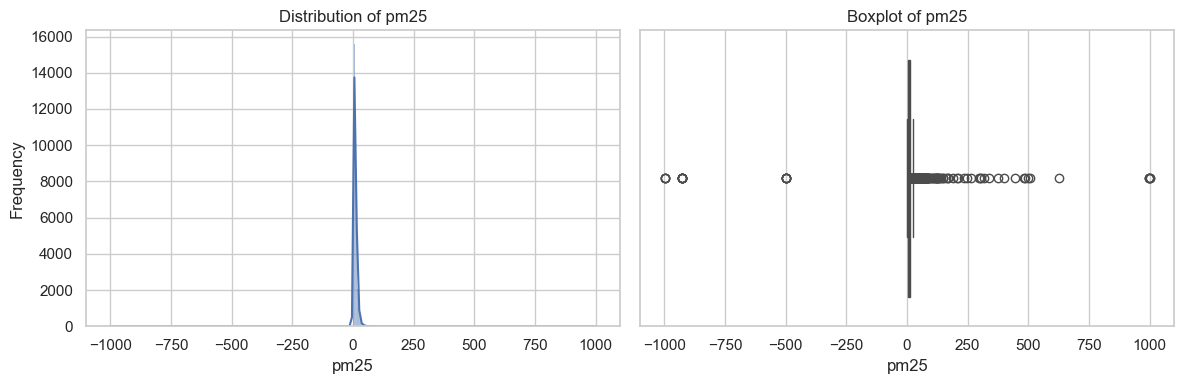

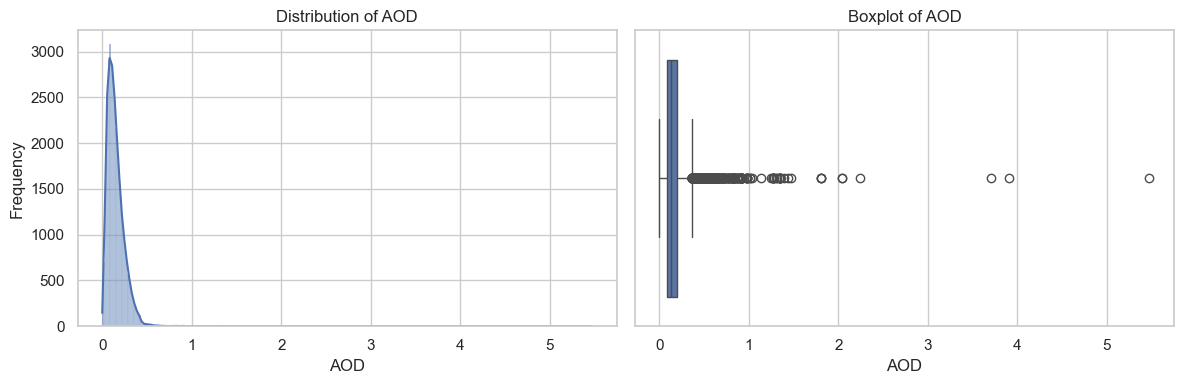

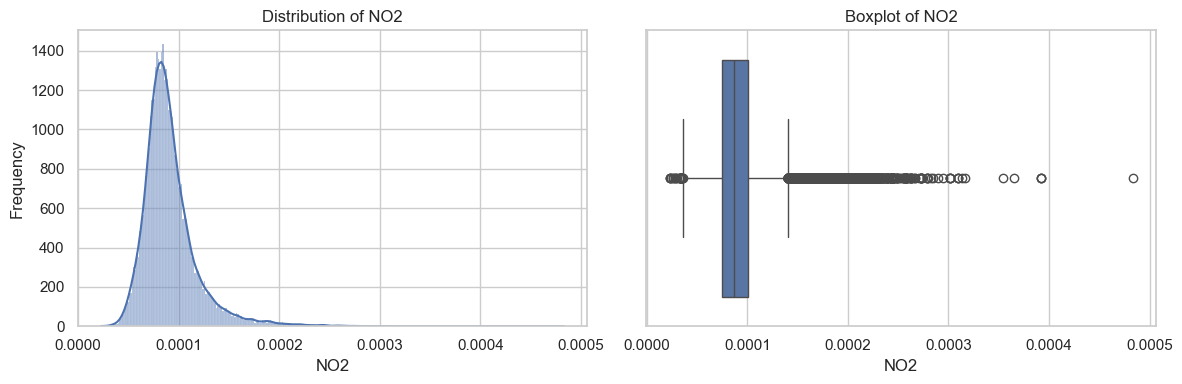

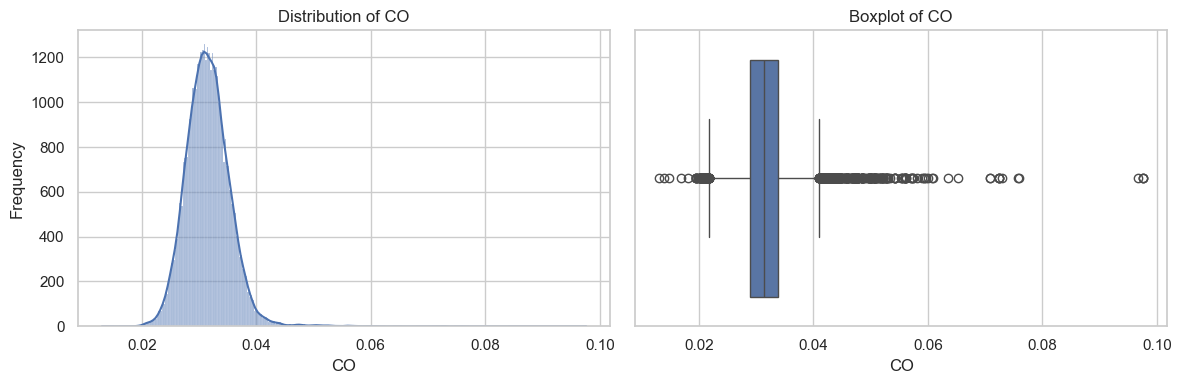

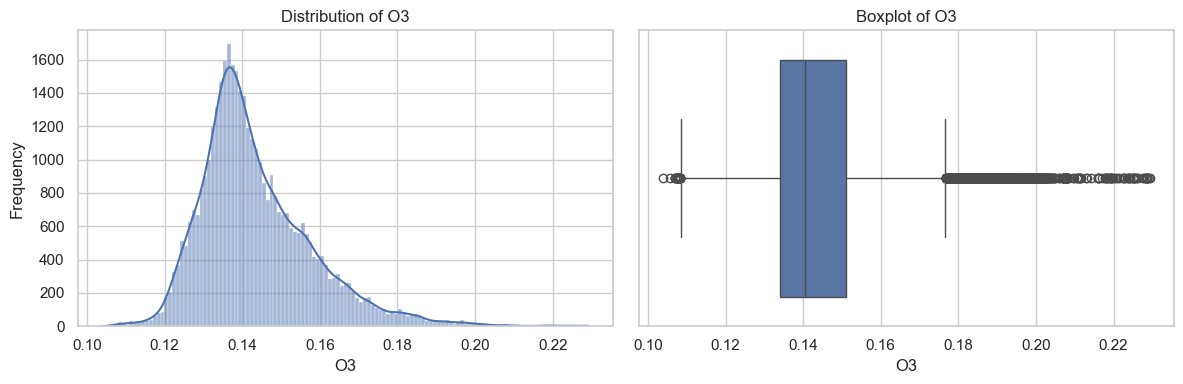

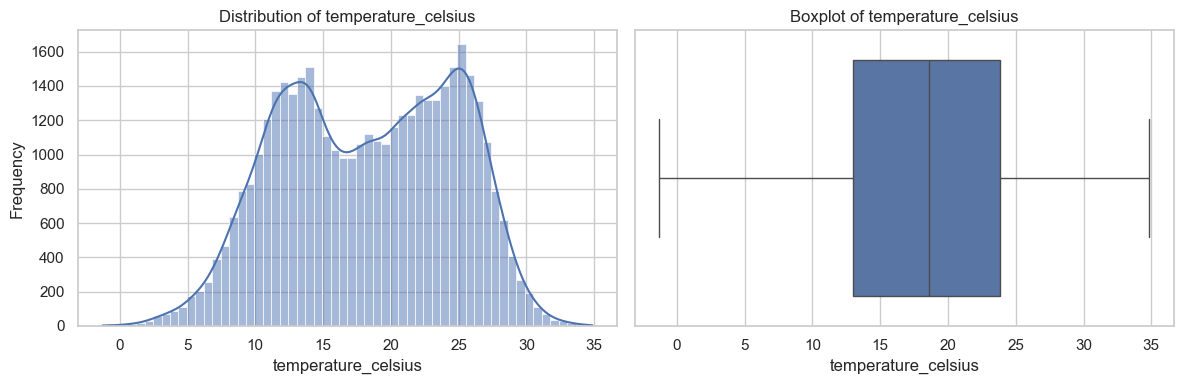

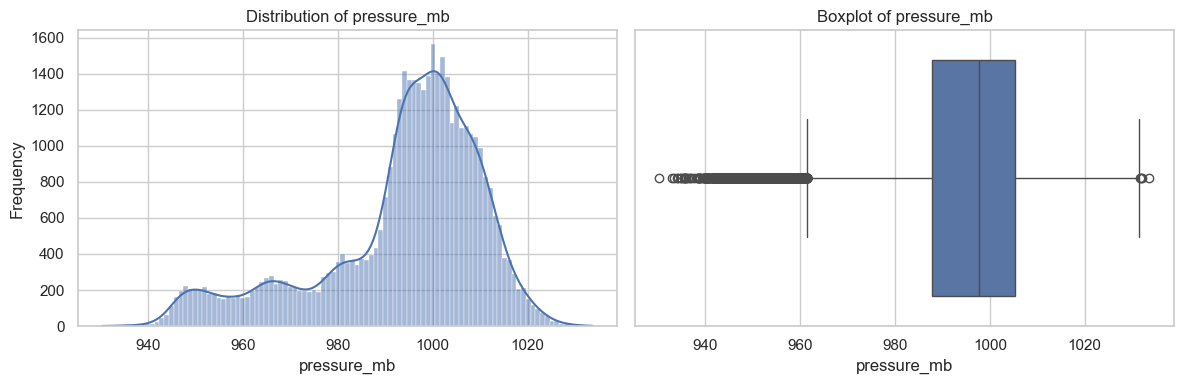

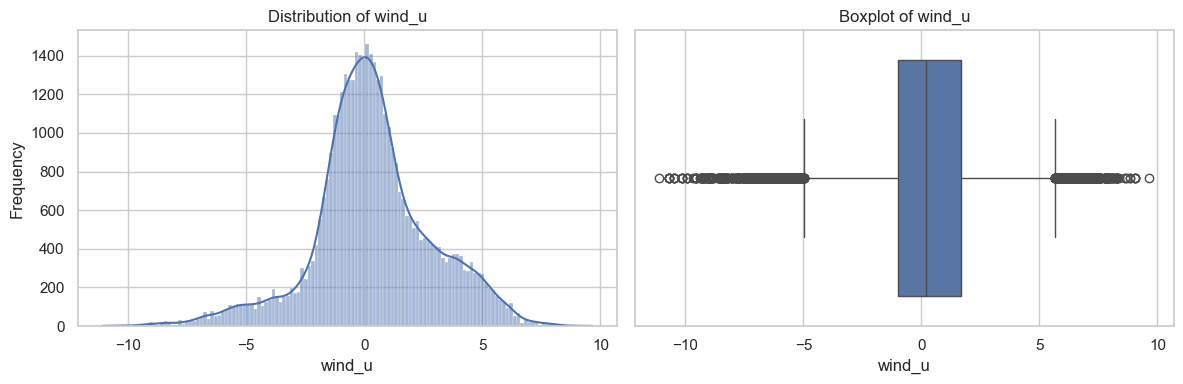

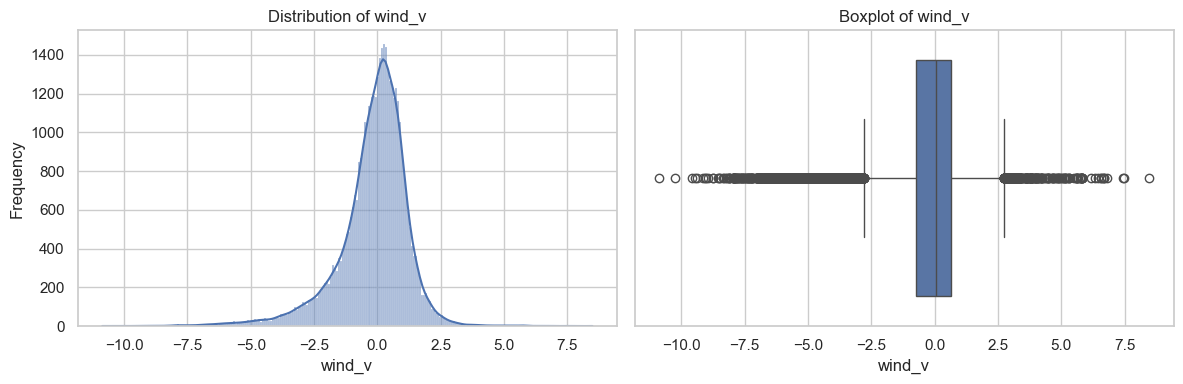

In [ ]:
# Set a consistent visual style
sns.set_theme(style="whitegrid")
# Numerical environmental variables
variables = [
    "pm25",
    "AOD",
    "NO2",
    "CO",
    "O3",
    "temperature_celsius",
    "pressure_mb",
    "wind_u",
    "wind_v",
]

# Create histograms and boxplots
for variable in variables:

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Histogram
    sns.histplot(data=combined, x=variable, kde=True, ax=axes[0])
    axes[0].set_title(f"Distribution of {variable}")
    axes[0].set_xlabel(variable)
    axes[0].set_ylabel("Frequency")

    # Boxplot
    sns.boxplot(data=combined, x=variable, ax=axes[1])
    axes[1].set_title(f"Boxplot of {variable}")
    axes[1].set_xlabel(variable)

    plt.tight_layout()
    plt.show()

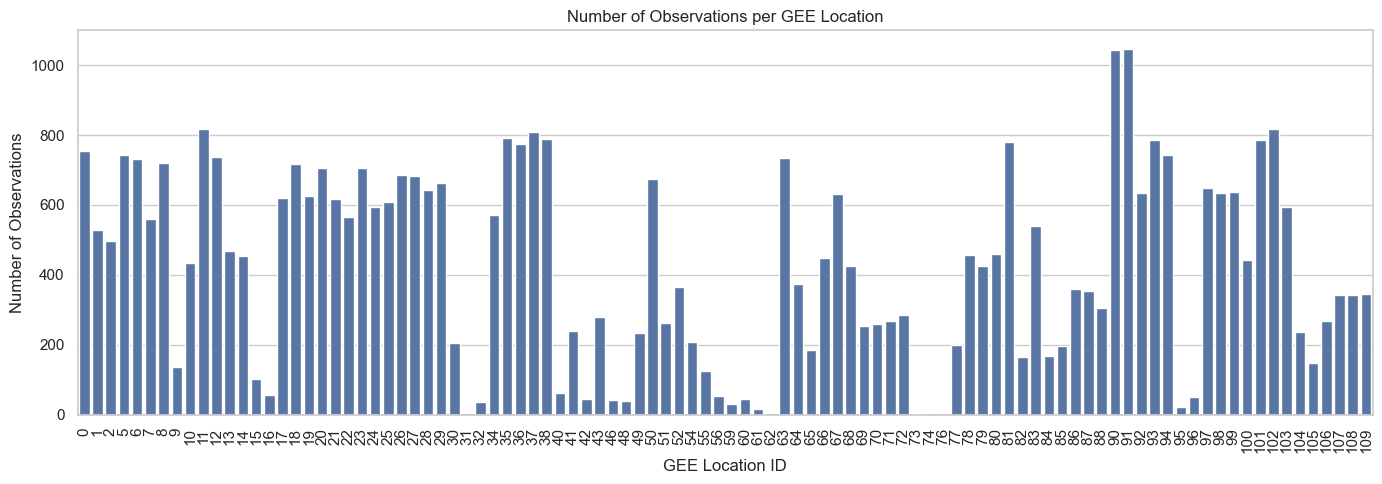

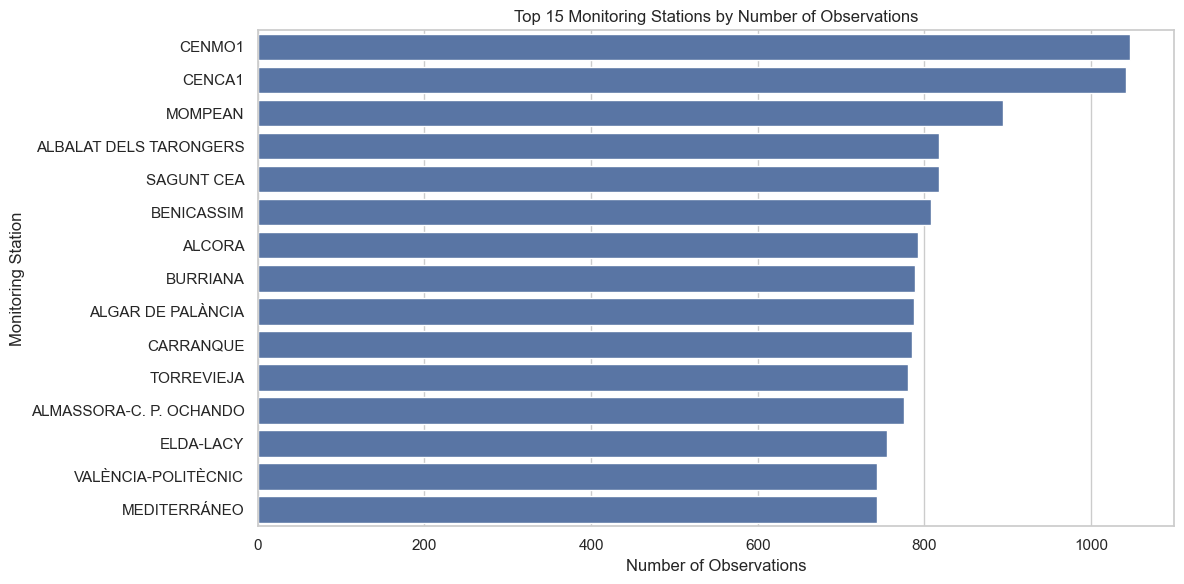

In [ ]:
# Bar charts for categorical identifiers
plt.figure(figsize=(14, 5))
sns.countplot(data=combined, x="id", order=sorted(combined["id"].unique()))
plt.title("Number of Observations per GEE Location")
plt.xlabel("GEE Location ID")
plt.ylabel("Number of Observations")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()
top_stations = combined["sensor_name"].value_counts().head(15)

plt.figure(figsize=(12, 6))

sns.barplot(x=top_stations.values, y=top_stations.index)

plt.title("Top 15 Monitoring Stations by Number of Observations")
plt.xlabel("Number of Observations")
plt.ylabel("Monitoring Station")

plt.tight_layout()
plt.show()

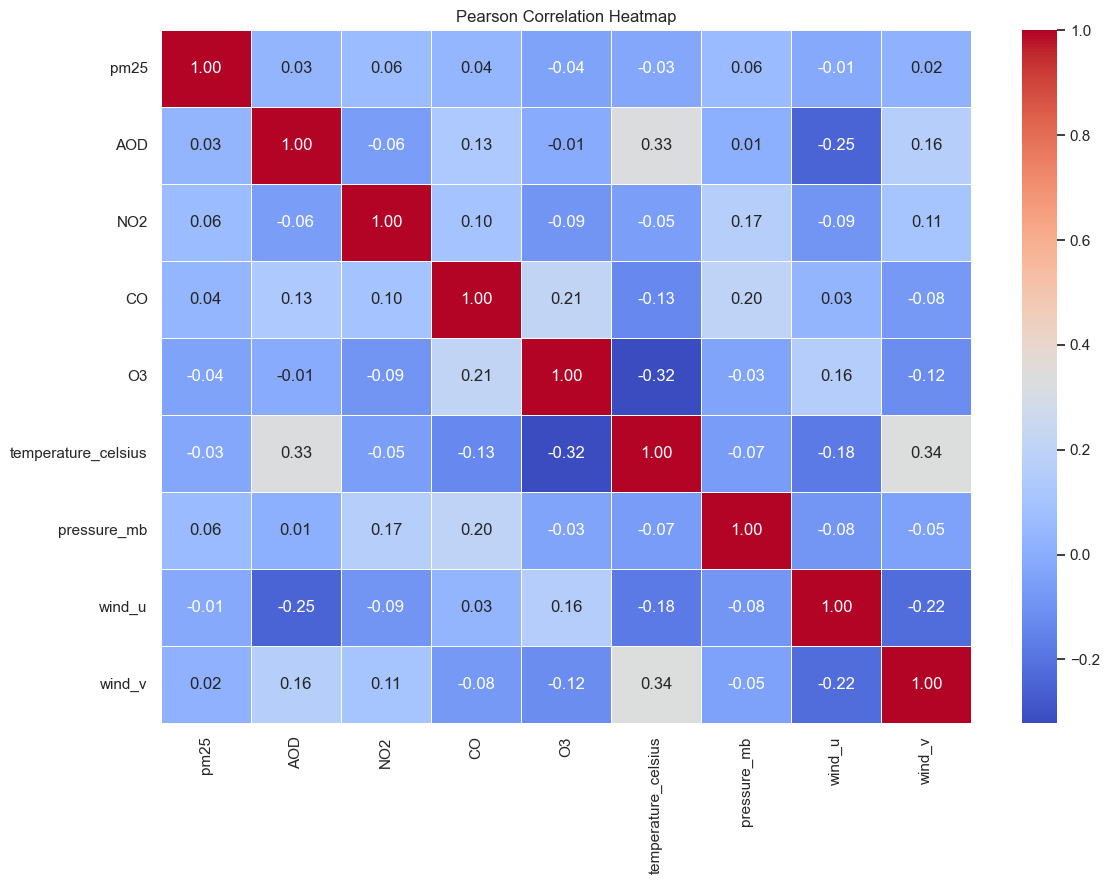

In [ ]:
# Calculate Pearson correlation
correlation_matrix = combined[variables].corr(method="pearson")

plt.figure(figsize=(12, 9))

sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)

plt.title("Pearson Correlation Heatmap")

plt.tight_layout()
plt.show()

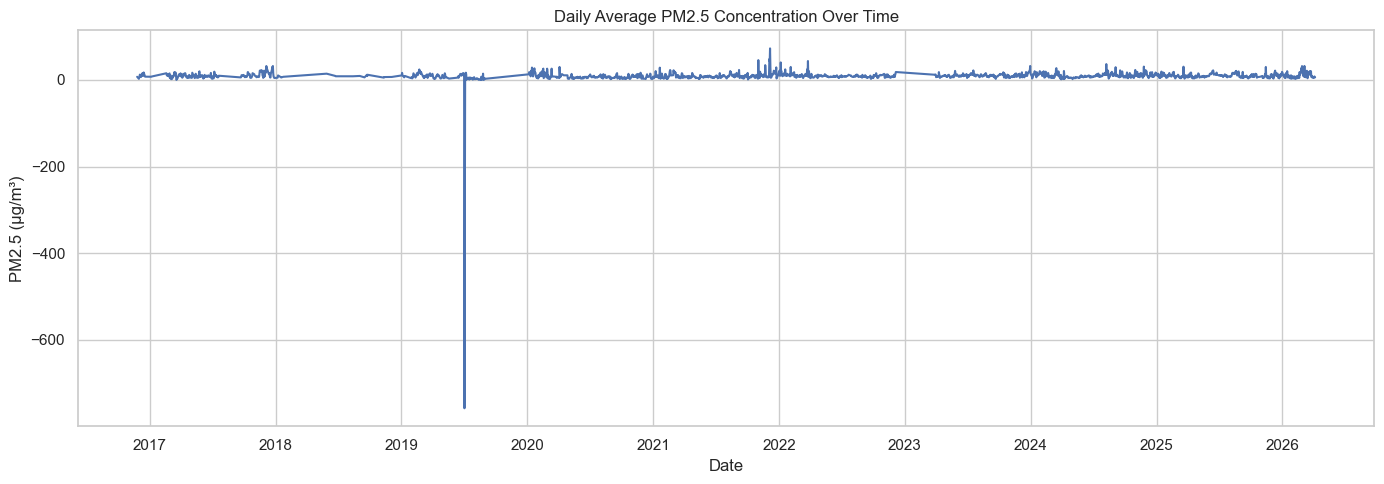

In [ ]:
# Temporal visualization
# Convert date into datetime format
combined["date"] = pd.to_datetime(combined["date"])

# Calculate daily average PM2.5
daily_pm25 = combined.groupby("date")["pm25"].mean().reset_index()

# Plot daily PM2.5
plt.figure(figsize=(14, 5))

sns.lineplot(data=daily_pm25, x="date", y="pm25")

plt.title("Daily Average PM2.5 Concentration Over Time")
plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")

plt.tight_layout()
plt.show()

### 5.1.4 Missingness and outliers (IQR, z-score, then Isolation Forest / LOF)

**Quantify missingness and inspect potential outliers**

In [ ]:
missing_summary = pd.DataFrame(
    {
        "Missing Values": combined.isnull().sum(),
        "Missing Percentage (%)": combined.isnull().mean() * 100,
    }
)
display(missing_summary)

print("\noutliers:")
numerical_variables = [
    "temperature_celsius",
    "pressure_mb",
    "wind_u",
    "wind_v",
    "NO2",
    "CO",
    "O3",
    "AOD",
    "pm25",
]

for variable in numerical_variables:
    Q1 = combined[variable].quantile(0.25)
    Q3 = combined[variable].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = combined[(combined[variable] < lower) | (combined[variable] > upper)]

    print(f"\n{variable}")
    print("Lower boundary:", round(lower, 4))
    print("Upper boundary:", round(upper, 4))
    print("Potential outliers:", len(outliers))

print("PM2.5 minimum:", combined["pm25"].min())
print("PM2.5 maximum:", combined["pm25"].max())

print("\nValues <= 0:")
print((combined["pm25"] <= 0).sum())

print("\nValues >= 500:")
print((combined["pm25"] >= 500).sum())

zscore_results = []

for variable in numerical_variables:

    mean = combined[variable].mean()
    std = combined[variable].std()

    z_scores = (combined[variable] - mean) / std

    outliers_count = (z_scores.abs() > 3).sum()

    zscore_results.append({"Variable": variable, "Z-score Outliers": outliers_count})

zscore_summary = pd.DataFrame(zscore_results)

display(zscore_summary)

,Missing Values,Missing Percentage (%)
date,0,0.000000
datetime_utc,0,0.000000
id,0,0.000000
latitude,0,0.000000
longitude,0,0.000000
temperature_celsius,0,0.000000
pressure_mb,0,0.000000
wind_u,0,0.000000
wind_v,0,0.000000
NO2,2410,5.776883



outliers:

temperature_celsius
Lower boundary: -3.2471
Upper boundary: 40.1295
Potential outliers: 0

pressure_mb
Lower boundary: 961.4563
Upper boundary: 1031.5916
Potential outliers: 3202

wind_u
Lower boundary: -4.9877
Upper boundary: 5.6671
Potential outliers: 2185

wind_v
Lower boundary: -2.7971
Upper boundary: 2.74
Potential outliers: 2290

NO2
Lower boundary: 0.0
Upper boundary: 0.0001
Potential outliers: 2096

CO
Lower boundary: 0.0218
Upper boundary: 0.041
Potential outliers: 573

O3
Lower boundary: 0.1085
Upper boundary: 0.1767
Potential outliers: 1263

AOD
Lower boundary: -0.0913
Upper boundary: 0.3668
Potential outliers: 1099

pm25
Lower boundary: -6.75
Upper boundary: 23.25
Potential outliers: 1634
PM2.5 minimum: -999.0
PM2.5 maximum: 1000.0

Values <= 0:
727

Values >= 500:
8


,Variable,Z-score Outliers
0,temperature_celsius,5
1,pressure_mb,67
2,wind_u,289
3,wind_v,766
4,NO2,744
5,CO,257
6,O3,466
7,AOD,300
8,pm25,75


### 5.1.5 Removal of missing / invalid PM2.5 (≤ 0 or ≥ 500) — counts reported

**Remove invalid PM2.5 observations**

In [ ]:
# Create a copy of the original dataset
combined_clean = combined.copy()

# Count invalid observations
missing_pm25 = combined_clean["pm25"].isnull().sum()
invalid_low = (combined_clean["pm25"] <= 0).sum()
invalid_high = (combined_clean["pm25"] >= 500).sum()

# Remove invalid observations
combined_clean = combined_clean[
    combined_clean["pm25"].notnull()
    & (combined_clean["pm25"] > 0)
    & (combined_clean["pm25"] < 500)
].copy()

# Display results
print("Original rows:", len(combined))
print("Missing PM2.5:", missing_pm25)
print("PM2.5 <= 0:", invalid_low)
print("PM2.5 >= 500:", invalid_high)
print("Total removed:", len(combined) - len(combined_clean))
print("Remaining rows:", len(combined_clean))
# Verify PM2.5 cleaning
print("Missing PM2.5 values:", combined_clean["pm25"].isnull().sum())
print("PM2.5 values <= 0:", (combined_clean["pm25"] <= 0).sum())
print("PM2.5 values >= 500:", (combined_clean["pm25"] >= 500).sum())
print("\nPM2.5 minimum:", combined_clean["pm25"].min())
print("PM2.5 maximum:", combined_clean["pm25"].max())
# Save the cleaned dataset
combined_clean.to_csv(f"{PROCESSED_DIR}/combined_clean.csv", index=False)

print("\nCleaned combined dataset saved successfully!")
print("Final shape:", combined_clean.shape)

Original rows: 41718
Missing PM2.5: 0
PM2.5 <= 0: 727
PM2.5 >= 500: 8
Total removed: 735
Remaining rows: 40983
Missing PM2.5 values: 0
PM2.5 values <= 0: 0
PM2.5 values >= 500: 0

PM2.5 minimum: 0.0066666666666666
PM2.5 maximum: 484.9815

Cleaned combined dataset saved successfully!
Final shape: (40983, 15)


### 5.1.4 (continued) Isolation Forest, LOF and PM2.5 correlation p-values on the cleaned data

In [ ]:
# ============================================================
# ADDITIONAL CALCULATIONS FOR exploratory_Data.csv
# (first half: outlier detection + correlation p-values; the time-series half is in 02_timeseries.ipynb)
# ============================================================

import numpy as np
import pandas as pd

from scipy.stats import pearsonr
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from statsmodels.tsa.stattools import pacf

# ============================================================
# 1. DEFINE THE VARIABLES
# ============================================================

# Atmospheric measurements and PM2.5.
# Latitude and longitude are excluded because they are
# geographic coordinates, not atmospheric measurements.

measurement_variables = [
    "temperature_celsius",
    "pressure_mb",
    "wind_u",
    "wind_v",
    "NO2",
    "CO",
    "O3",
    "AOD",
    "pm25",
]
combined_clean = pd.read_csv(f"{PROCESSED_DIR}/combined_clean.csv")
# Keep only variables that exist in the cleaned dataset.
measurement_variables = [
    variable for variable in measurement_variables if variable in combined_clean.columns
]

# Environmental predictors only (PM2.5 is the target).
predictor_variables_for_pvalues = [
    variable for variable in measurement_variables if variable != "pm25"
]


# ============================================================
# 2. ISOLATION FOREST AND LOF OUTLIER DETECTION
# ============================================================

print("=" * 65)
print("ADDITIONAL CALCULATIONS")
print("=" * 65)

print("\nCalculating Isolation Forest and LOF outliers...")

outlier_results = {}

for variable in measurement_variables:

    values = (
        pd.to_numeric(combined_clean[variable], errors="coerce")
        .dropna()
        .to_numpy()
        .reshape(-1, 1)
    )

    n_values = len(values)

    # Check whether enough different values are available.
    if n_values < 3 or len(np.unique(values)) < 2:

        outlier_results[variable] = {
            "n_out_if": np.nan,
            "pct_out_if": np.nan,
            "n_out_lof": np.nan,
            "pct_out_lof": np.nan,
        }

        continue

    # -----------------------------
    # Isolation Forest
    # -----------------------------

    isolation_model = IsolationForest(
        contamination="auto", random_state=42, n_estimators=100, n_jobs=-1
    )

    isolation_predictions = isolation_model.fit_predict(values)

    n_out_if = int((isolation_predictions == -1).sum())
    pct_out_if = n_out_if / n_values * 100

    # -----------------------------
    # Local Outlier Factor (LOF)
    # -----------------------------

    n_neighbors = min(20, n_values - 1)

    lof_model = LocalOutlierFactor(
        n_neighbors=n_neighbors, contamination="auto", algorithm="kd_tree", n_jobs=-1
    )

    lof_predictions = lof_model.fit_predict(values)

    n_out_lof = int((lof_predictions == -1).sum())
    pct_out_lof = n_out_lof / n_values * 100

    # Store results.
    outlier_results[variable] = {
        "n_out_if": n_out_if,
        "pct_out_if": pct_out_if,
        "n_out_lof": n_out_lof,
        "pct_out_lof": pct_out_lof,
    }

    print(
        f"{variable}: "
        f"IF = {n_out_if} ({pct_out_if:.2f}%), "
        f"LOF = {n_out_lof} ({pct_out_lof:.2f}%)"
    )


# ============================================================
# 3. PEARSON CORRELATION P-VALUES WITH PM2.5
# ============================================================

print("\nCalculating Pearson correlation p-values...")

target_pvalues = {}

for variable in predictor_variables_for_pvalues:

    paired_data = combined_clean[["pm25", variable]].dropna()

    # Pearson correlation requires at least 3 pairs
    # and variation in both variables.
    if (
        len(paired_data) >= 3
        and paired_data["pm25"].nunique() > 1
        and paired_data[variable].nunique() > 1
    ):

        correlation, p_value = pearsonr(paired_data["pm25"], paired_data[variable])

        target_pvalues[variable] = p_value

        print(
            f"PM2.5 vs {variable}: "
            f"correlation = {correlation:.4f}, "
            f"p-value = {p_value:.6g}"
        )

    else:
        target_pvalues[variable] = np.nan


# PM2.5 is the target itself, so it does not receive
# a correlation p-value against itself.
target_pvalues["pm25"] = np.nan


# ------------------------------------------------------------
# DISPLAY (outlier detection and p-values)
# ------------------------------------------------------------
print("\nOutlier detection results:")
display(pd.DataFrame.from_dict(outlier_results, orient="index").round(4))

print("\nPM2.5 correlation p-values:")
display(
    pd.DataFrame(
        list(target_pvalues.items()), columns=["variable", "target_pval"]
    ).round(6)
)



### 5.1.6 Duplicates (all columns and key fields)

**Inspect duplicates**

In [ ]:
print("Exact duplicate rows:", combined_clean.duplicated().sum())
duplicate_keys = combined_clean.duplicated(
    subset=["date", "latitude", "longitude", "id"]
)

print("Duplicate date-location records:", duplicate_keys.sum())

Exact duplicate rows: 0
Duplicate date-location records: 0


### 5.1.7 Relationships — Pearson / Spearman, |r| > 0.9, VIF

**Correlation analysis**

In [ ]:
# Calculate Pearson and Spearman correlations
# Select environmental variables and PM2.5
correlation_variables = [
    "pm25",
    "temperature_celsius",
    "pressure_mb",
    "wind_u",
    "wind_v",
    "NO2",
    "CO",
    "O3",
    "AOD",
]

# Calculate Pearson correlation
pearson_corr = combined_clean[correlation_variables].corr(method="pearson")

# Calculate Spearman correlation
spearman_corr = combined_clean[correlation_variables].corr(method="spearman")

print("PEARSON CORRELATION")
display(pearson_corr.round(3))

print("SPEARMAN CORRELATION")
display(spearman_corr.round(3))

# Identify highly correlated predictors
# Exclude the target variable
predictor_variables = [
    "temperature_celsius",
    "pressure_mb",
    "wind_u",
    "wind_v",
    "NO2",
    "CO",
    "O3",
    "AOD",
]


# Extract pairs with absolute correlation > 0.9
def find_high_correlations(correlation_matrix):
    pairs = []

    for i in range(len(predictor_variables)):
        for j in range(i + 1, len(predictor_variables)):

            value = correlation_matrix.loc[
                predictor_variables[i], predictor_variables[j]
            ]

            if abs(value) > 0.9:
                pairs.append(
                    {
                        "Variable 1": predictor_variables[i],
                        "Variable 2": predictor_variables[j],
                        "Correlation": round(value, 3),
                    }
                )

    return pd.DataFrame(pairs)


print("Highly correlated predictors - Pearson:")
display(find_high_correlations(pearson_corr))

print("Highly correlated predictors - Spearman:")
display(find_high_correlations(spearman_corr))

PEARSON CORRELATION


,pm25,temperature_celsius,pressure_mb,wind_u,wind_v,NO2,CO,O3,AOD
pm25,1.000,-0.006,0.113,-0.079,0.059,0.159,0.041,-0.087,0.094
temperature_celsius,-0.006,1.000,-0.062,-0.179,0.338,-0.055,-0.126,-0.320,0.332
pressure_mb,0.113,-0.062,1.000,-0.086,-0.044,0.166,0.198,-0.034,0.017
wind_u,-0.079,-0.179,-0.086,1.000,-0.218,-0.089,0.033,0.162,-0.247
wind_v,0.059,0.338,-0.044,-0.218,1.000,0.106,-0.075,-0.120,0.164
NO2,0.159,-0.055,0.166,-0.089,0.106,1.000,0.100,-0.094,-0.062
CO,0.041,-0.126,0.198,0.033,-0.075,0.100,1.000,0.210,0.133
O3,-0.087,-0.320,-0.034,0.162,-0.120,-0.094,0.210,1.000,-0.010
AOD,0.094,0.332,0.017,-0.247,0.164,-0.062,0.133,-0.010,1.000


SPEARMAN CORRELATION


,pm25,temperature_celsius,pressure_mb,wind_u,wind_v,NO2,CO,O3,AOD
pm25,1.000,0.064,0.167,-0.164,0.097,0.247,0.036,-0.135,0.180
temperature_celsius,0.064,1.000,-0.090,-0.242,0.392,0.065,-0.182,-0.299,0.403
pressure_mb,0.167,-0.090,1.000,-0.111,-0.075,0.143,0.182,-0.053,0.020
wind_u,-0.164,-0.242,-0.111,1.000,-0.207,-0.111,0.045,0.117,-0.367
wind_v,0.097,0.392,-0.075,-0.207,1.000,0.136,-0.068,-0.071,0.261
NO2,0.247,0.065,0.143,-0.111,0.136,1.000,0.105,-0.057,-0.040
CO,0.036,-0.182,0.182,0.045,-0.068,0.105,1.000,0.278,0.032
O3,-0.135,-0.299,-0.053,0.117,-0.071,-0.057,0.278,1.000,0.007
AOD,0.180,0.403,0.020,-0.367,0.261,-0.040,0.032,0.007,1.000


Highly correlated predictors - Pearson:


""


Highly correlated predictors - Spearman:


""


In [ ]:
# Calculate VIF
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Select predictors and temporarily remove rows with missing values
vif_data = combined_clean[predictor_variables].dropna()

# Add a constant
X_vif = add_constant(vif_data)

# Calculate VIF for each predictor
vif_results = pd.DataFrame(
    {
        "Variable": predictor_variables,
        "VIF": [
            variance_inflation_factor(X_vif.values, i + 1)
            for i in range(len(predictor_variables))
        ],
    }
)

display(vif_results.round(3))

,Variable,VIF
0,temperature_celsius,1.406
1,pressure_mb,1.084
2,wind_u,1.139
3,wind_v,1.181
4,NO2,1.082
5,CO,1.144
6,O3,1.203
7,AOD,1.236


### 5.1.8 PM2.5–predictor relationships — seasonal / station differences, meteorology and the PM2.5–AOD link

**Study PM2.5–predictor relationships**

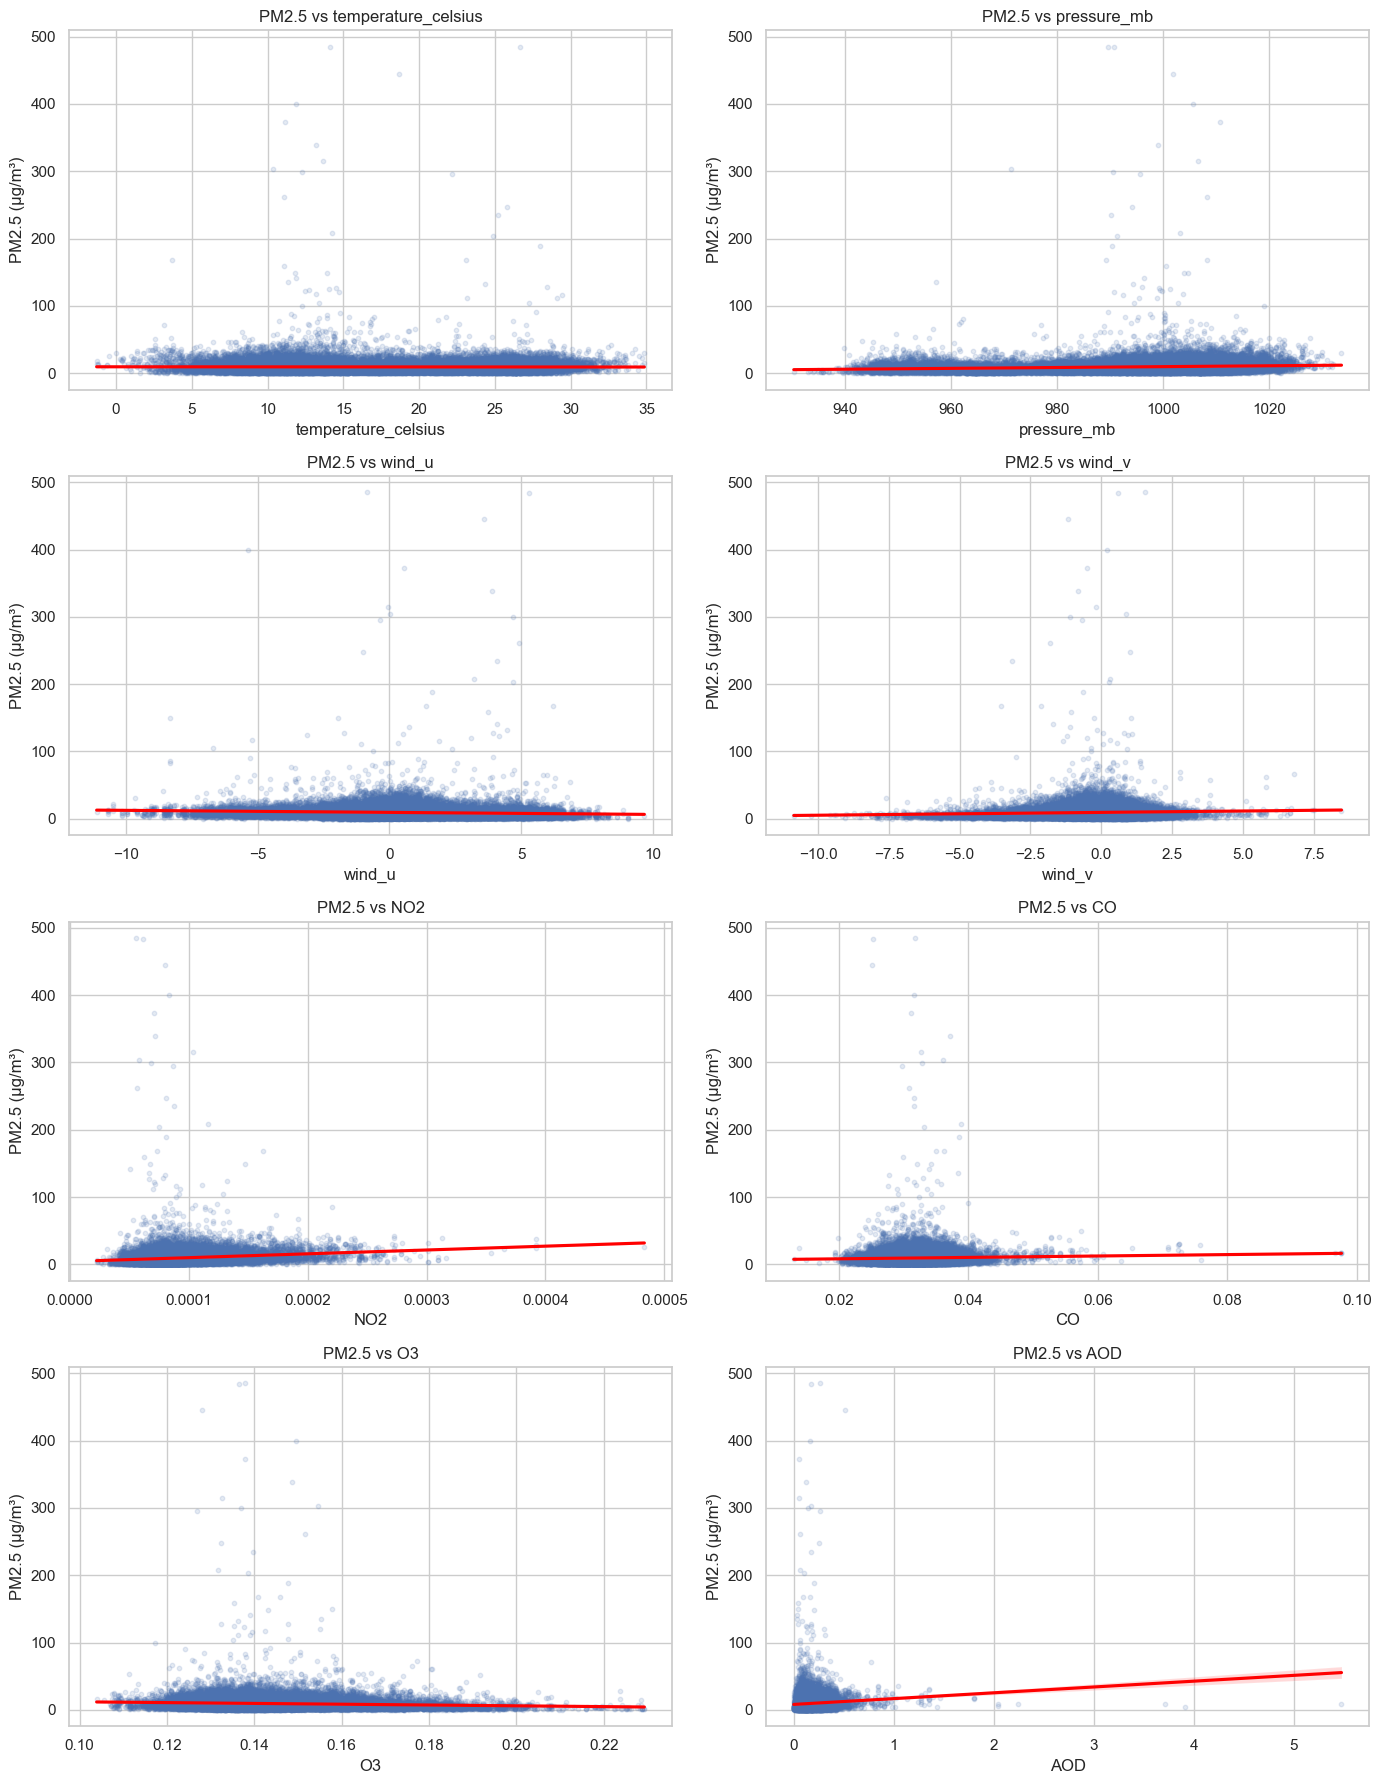

In [ ]:
# PM2.5 relationships with environmental predictors

fig, axes = plt.subplots(4, 2, figsize=(14, 18))

axes = axes.flatten()

for i, variable in enumerate(predictor_variables):

    sns.regplot(
        data=combined_clean,
        x=variable,
        y="pm25",
        ax=axes[i],
        scatter_kws={"alpha": 0.15, "s": 10},
        line_kws={"color": "red"},
    )

    axes[i].set_title(f"PM2.5 vs {variable}")
    axes[i].set_xlabel(variable)
    axes[i].set_ylabel("PM2.5 (µg/m³)")

plt.tight_layout()
plt.show()



In [ ]:
# Extract the month from the date
combined_clean["date"] = pd.to_datetime(combined_clean["date"])

combined_clean["month"] = combined_clean["date"].dt.month

# Assign a season to each observation
season_mapping = {
    12: "Winter",
    1: "Winter",
    2: "Winter",
    3: "Spring",
    4: "Spring",
    5: "Spring",
    6: "Summer",
    7: "Summer",
    8: "Summer",
    9: "Autumn",
    10: "Autumn",
    11: "Autumn",
}

combined_clean["season"] = combined_clean["month"].map(season_mapping)

display(combined_clean[["date", "month", "season"]].head(10))
# Calculate PM2.5 statistics for each season

seasonal_stats = combined_clean.groupby("season")["pm25"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

# Display seasons in chronological order
season_order = ["Winter", "Spring", "Summer", "Autumn"]

seasonal_stats = seasonal_stats.reindex(season_order)

display(seasonal_stats.round(2))

,date,month,season
0,2016-11-25,11,Autumn
1,2016-11-25,11,Autumn
2,2016-11-30,11,Autumn
3,2016-11-30,11,Autumn
4,2016-12-02,12,Winter
5,2016-12-02,12,Winter
6,2016-12-02,12,Winter
7,2016-12-02,12,Winter
8,2016-12-02,12,Winter
9,2016-12-02,12,Winter


,count,mean,median,std,min,max
season,,,,,,
Winter,8938,10.94,8.77,11.72,0.03,399.40
Spring,9276,8.25,6.83,7.40,0.01,303.50
Summer,12766,9.59,8.50,7.21,0.02,234.88
Autumn,10003,9.08,7.47,12.02,0.01,484.98


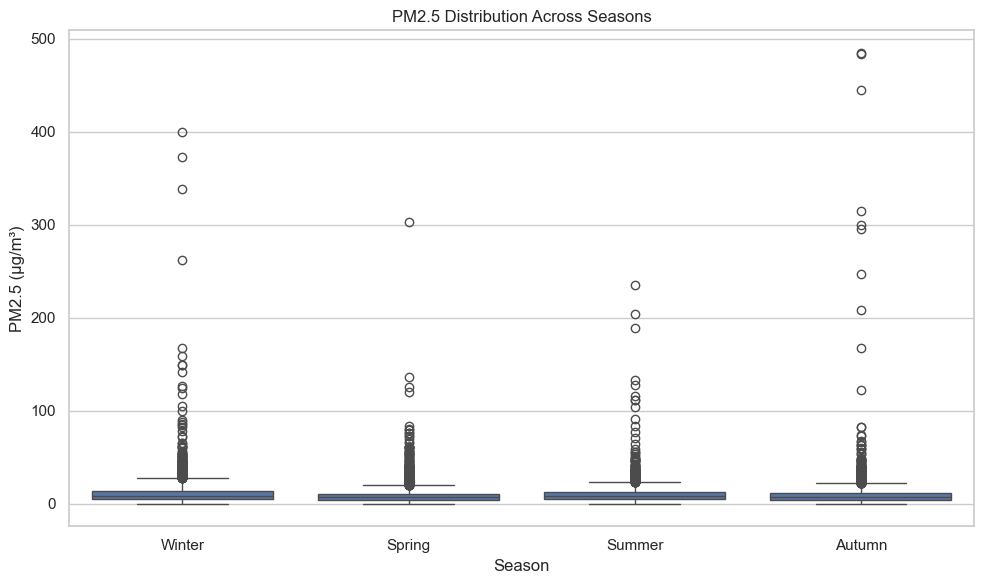

In [ ]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=combined_clean,
    x="season",
    y="pm25",
    order=["Winter", "Spring", "Summer", "Autumn"],
)

plt.title("PM2.5 Distribution Across Seasons")
plt.xlabel("Season")
plt.ylabel("PM2.5 (µg/m³)")

plt.tight_layout()
plt.show()

In [ ]:
# station
station_stats = combined_clean.groupby("sensor_name")["pm25"].agg(
    ["count", "mean", "median", "std"]
)

# Sort stations by their mean PM2.5 concentration
station_stats = station_stats.sort_values(by="mean", ascending=False)

display(station_stats.round(2))

,count,mean,median,std
sensor_name,,,,
Gibraltar,36,44.94,44.13,14.93
Barcelona - Porta - Can Dragó,364,15.02,13.06,9.15
HOSTELERÍA,643,14.57,11.14,26.11
PUENTE MAYORGA,617,14.54,14.15,6.29
FR03006,260,14.35,13.45,7.60
...,...,...,...,...
BENICASSIM,770,4.99,3.90,5.47
ALGAR DE PALÀNCIA,771,4.65,3.76,3.98
ALBALAT DELS TARONGERS,798,3.74,2.50,4.01


In [ ]:
# Number of different sensor names associated with each GEE ID
ids_per_sensor = combined_clean.groupby("sensor_name")["id"].nunique()

# Number of different GEE IDs associated with each sensor name
sensors_per_id = combined_clean.groupby("id")["sensor_name"].nunique()

print("Maximum IDs per sensor name:", ids_per_sensor.max())
print("Sensor names associated with multiple IDs:", (ids_per_sensor > 1).sum())

print("\nMaximum sensor names per ID:", sensors_per_id.max())
print("IDs associated with multiple sensor names:", (sensors_per_id > 1).sum())
ids_per_sensor = combined_clean.groupby("sensor_name")["id"].nunique()

multiple_id_sensors = ids_per_sensor[ids_per_sensor > 1]

display(multiple_id_sensors)

Maximum IDs per sensor name: 2
Sensor names associated with multiple IDs: 4

Maximum sensor names per ID: 1
IDs associated with multiple sensor names: 0


sensor_name
LA ALJORRA          2
MOLINA DE SEGURA    2
MOMPEAN             2
SAN BASILIO         2
Name: id, dtype: int64

,count,mean,median,std
sensor_name,,,,
Gibraltar,36,44.94,44.13,14.93
Barcelona - Porta - Can Dragó,364,15.02,13.06,9.15
HOSTELERÍA,643,14.57,11.14,26.11
PUENTE MAYORGA,617,14.54,14.15,6.29
FR03006,260,14.35,13.45,7.60
...,...,...,...,...
BENICASSIM,770,4.99,3.90,5.47
ALGAR DE PALÀNCIA,771,4.65,3.76,3.98
ALBALAT DELS TARONGERS,798,3.74,2.50,4.01


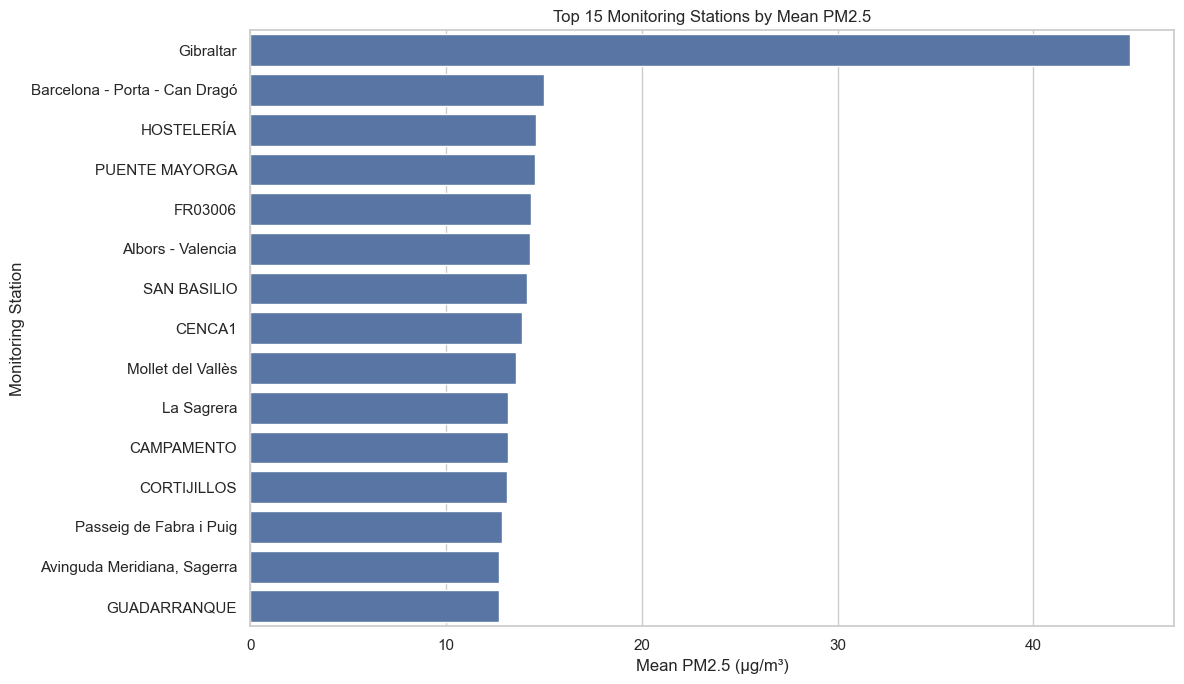

In [ ]:
station_stats = combined_clean.groupby("sensor_name")["pm25"].agg(
    ["count", "mean", "median", "std"]
)

# Sort stations by their mean PM2.5 concentration
station_stats = station_stats.sort_values(by="mean", ascending=False)

display(station_stats.round(2))
top_15_stations = station_stats.head(15)

plt.figure(figsize=(12, 7))

sns.barplot(data=top_15_stations.reset_index(), x="mean", y="sensor_name")

plt.title("Top 15 Monitoring Stations by Mean PM2.5")
plt.xlabel("Mean PM2.5 (µg/m³)")
plt.ylabel("Monitoring Station")

plt.tight_layout()
plt.show()

In [ ]:
#PM2.5_AOD with wind
combined_clean["wind_speed"] = np.sqrt(
    combined_clean["wind_u"] ** 2 + combined_clean["wind_v"] ** 2
)

display(combined_clean["wind_speed"].describe())
combined_clean["wind_category"] = pd.qcut(
    combined_clean["wind_speed"], q=3, labels=["Low wind", "Medium wind", "High wind"]
)

print(combined_clean["wind_category"].value_counts())
wind_results = []

for category, group in combined_clean.groupby("wind_category", observed=True):

    wind_results.append(
        {
            "Wind condition": category,
            "Observations": len(group),
            "Pearson": group["pm25"].corr(group["AOD"], method="pearson"),
            "Spearman": group["pm25"].corr(group["AOD"], method="spearman"),
        }
    )

wind_corr = pd.DataFrame(wind_results)

display(wind_corr.round(3))

count    40983.000000
mean         2.294713
std          1.787071
min          0.010350
25%          0.984691
50%          1.667193
75%          3.228056
max         13.261387
Name: wind_speed, dtype: float64

wind_category
Low wind       13663
Medium wind    13663
High wind      13657
Name: count, dtype: int64


,Wind condition,Observations,Pearson,Spearman
0,Low wind,13663,0.085,0.116
1,Medium wind,13663,0.059,0.102
2,High wind,13657,0.117,0.295


In [ ]:
# PM2.5_AOD with Temp
combined_clean["temperature_category"] = pd.qcut(
    combined_clean["temperature_celsius"],
    q=3,
    labels=["Low temperature", "Medium temperature", "High temperature"],
)

print(combined_clean["temperature_category"].value_counts())

temperature_results = []

for category, group in combined_clean.groupby("temperature_category", observed=True):
    temperature_results.append(
        {
            "Temperature condition": category,
            "Observations": len(group),
            "Pearson": group["pm25"].corr(group["AOD"], method="pearson"),
            "Spearman": group["pm25"].corr(group["AOD"], method="spearman"),
        }
    )

temperature_corr = pd.DataFrame(temperature_results)

display(temperature_corr.round(3))

temperature_category
Low temperature       13661
Medium temperature    13661
High temperature      13661
Name: count, dtype: int64


,Temperature condition,Observations,Pearson,Spearman
0,Low temperature,13661,0.076,0.190
1,Medium temperature,13661,0.131,0.167
2,High temperature,13661,0.126,0.202


In [ ]:
# PM2.5_AOD with season
season_results = []

for season, group in combined_clean.groupby("season", observed=True):
    season_results.append(
        {
            "Season": season,
            "Observations": len(group),
            "Mean PM2.5": group["pm25"].mean(),
            "Pearson": group["pm25"].corr(group["AOD"], method="pearson"),
            "Spearman": group["pm25"].corr(group["AOD"], method="spearman"),
        }
    )

season_corr = pd.DataFrame(season_results)

display(season_corr.round(3))

,Season,Observations,Mean PM2.5,Pearson,Spearman
0,Autumn,10003,9.083,0.108,0.214
1,Spring,9276,8.251,0.113,0.162
2,Summer,12766,9.594,0.154,0.209
3,Winter,8938,10.935,0.121,0.250


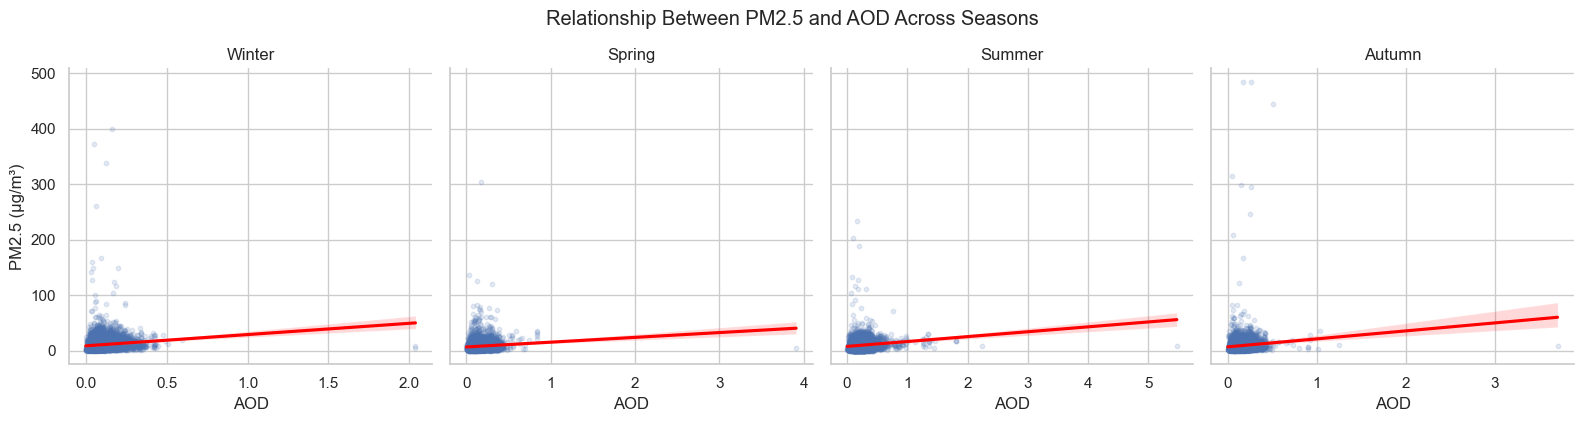

In [ ]:
g = sns.lmplot(
    data=combined_clean,
    x="AOD",
    y="pm25",
    col="season",
    col_order=["Winter", "Spring", "Summer", "Autumn"],
    height=4,
    aspect=1,
    scatter_kws={"alpha": 0.15, "s": 10},
    line_kws={"color": "red"},
    facet_kws={"sharex": False, "sharey": True},
)

g.set_axis_labels("AOD", "PM2.5 (µg/m³)")
g.set_titles("{col_name}")
g.fig.suptitle("Relationship Between PM2.5 and AOD Across Seasons", y=1.05)

plt.show()

### 5.1.9 Target distribution, extreme events and proportions above 25 and 50 µg/m³

**PM2.5 target distribution and extreme pollution events**

count       40983.000000
mean            9.457765
std             9.729713
min             0.006667
25%             4.673864
50%             7.851176
75%            12.086667
max           484.981500
skewness       17.829102
kurtosis      651.672107
Name: pm25, dtype: float64

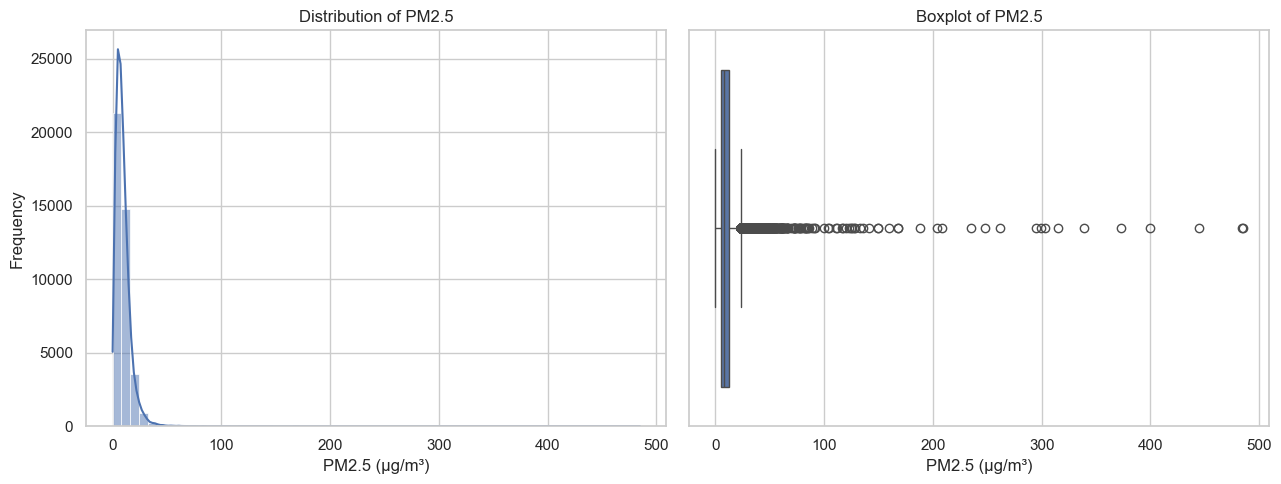

Total observations: 40983

PM2.5 above 25 µg/m³:
Count: 1223
Percentage: 2.98 %

PM2.5 above 50 µg/m³:
Count: 117
Percentage: 0.29 %


In [ ]:
pm25_stats = combined_clean["pm25"].describe()

pm25_stats["skewness"] = combined_clean["pm25"].skew()
pm25_stats["kurtosis"] = combined_clean["pm25"].kurtosis()

display(pm25_stats)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(data=combined_clean, x="pm25", bins=60, kde=True, ax=axes[0])
axes[0].set_title("Distribution of PM2.5")
axes[0].set_xlabel("PM2.5 (µg/m³)")
axes[0].set_ylabel("Frequency")

sns.boxplot(data=combined_clean, x="pm25", ax=axes[1])
axes[1].set_title("Boxplot of PM2.5")
axes[1].set_xlabel("PM2.5 (µg/m³)")

plt.tight_layout()
plt.show()
# Calculate proportions above 25 and 50 µg/m³
total = len(combined_clean)

above_25 = (combined_clean["pm25"] > 25).sum()
above_50 = (combined_clean["pm25"] > 50).sum()

print("Total observations:", total)

print("\nPM2.5 above 25 µg/m³:")
print("Count:", above_25)
print("Percentage:", round(above_25 / total * 100, 2), "%")

print("\nPM2.5 above 50 µg/m³:")
print("Count:", above_50)
print("Percentage:", round(above_50 / total * 100, 2), "%")

## 5.3 Preprocessing without data leakage

**Preprocessing and cleaning**

In [ ]:
# ============================================================
# SECTION 5.3 — PREPROCESSING WITHOUT DATA LEAKAGE
# ============================================================

import pandas as pd
import numpy as np

from functools import partial
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.preprocessing import RobustScaler
from sklearn.feature_selection import SelectKBest, mutual_info_regression
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ============================================================
# 1. LOAD AND PREPARE THE CLEANED COMBINED DATASET
# ============================================================

df = pd.read_csv(f"{PROCESSED_DIR}/combined_clean.csv")

print("Dataset shape:", df.shape)
print(df.head())

# Convert date to datetime
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Remove rows with invalid dates because they cannot be
# assigned to chronological training/validation/test periods.
invalid_dates = df["date"].isna().sum()
print("Rows with invalid dates:", invalid_dates)

df = df.dropna(subset=["date"]).copy()

# Define target and environmental predictors
target = "pm25"

sentinel_features = ["NO2", "CO", "O3"]

other_numerical_features = [
    "temperature_celsius",
    "pressure_mb",
    "wind_u",
    "wind_v",
    "AOD",
]

continuous_features = sentinel_features + other_numerical_features

# Convert numerical columns to numeric values
for column in continuous_features + [target]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# The target cannot be imputed.
# Remove rows where PM2.5 is missing.
missing_target = df[target].isna().sum()
print("Rows with missing PM2.5:", missing_target)

df = df.dropna(subset=[target]).copy()

# Sort chronologically
df = df.sort_values("date").reset_index(drop=True)

print("\nDataset after preparation:")
print("Observations:", len(df))
print("First date:", df["date"].min())
print("Last date:", df["date"].max())
print("Unique dates:", df["date"].nunique())
print("Unique stations:", df["id"].nunique())


# ============================================================
# 5.3.1 — MISSING VALUES
# ============================================================

# ------------------------------------------------------------
# A. Missingness by variable
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("5.3.1 — MISSING VALUES")
print("=" * 60)

missing_report = pd.DataFrame(
    {
        "Missing_Count": df[continuous_features].isna().sum(),
        "Missing_Percentage": df[continuous_features].isna().mean() * 100,
    }
)

print("\nMissingness by variable:")
print(missing_report.round(2))


# ------------------------------------------------------------
# B. Missingness by month for NO2, CO and O3
# ------------------------------------------------------------

print("\nMISSINGNESS BY MONTH")

for variable in sentinel_features:

    monthly_group = df.groupby(df["date"].dt.to_period("M"))[variable]

    monthly_missing = pd.DataFrame(
        {
            "Total_Records": monthly_group.size(),
            "Missing_Count": monthly_group.apply(lambda x: x.isna().sum()),
        }
    )

    monthly_missing["Missing_Percentage"] = (
        monthly_missing["Missing_Count"] / monthly_missing["Total_Records"] * 100
    )

    print(f"\n{variable}:")
    print(monthly_missing[monthly_missing["Missing_Count"] > 0].round(2))


# ------------------------------------------------------------
# C. Missingness by station for NO2, CO and O3
# ------------------------------------------------------------

print("\nMISSINGNESS BY STATION")

for variable in sentinel_features:

    station_group = df.groupby("id")[variable]

    station_missing = pd.DataFrame(
        {
            "Total_Records": station_group.size(),
            "Missing_Count": station_group.apply(lambda x: x.isna().sum()),
        }
    )

    station_missing["Missing_Percentage"] = (
        station_missing["Missing_Count"] / station_missing["Total_Records"] * 100
    )

    print(f"\n{variable}:")
    print(station_missing[station_missing["Missing_Count"] > 0].round(2))


# ------------------------------------------------------------
# D. Check categorical variables
# ------------------------------------------------------------

categorical_columns = df.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

print("\nCategorical columns:")
print(categorical_columns)

if categorical_columns:
    print("\nCategorical missing values:")
    print(df[categorical_columns].isna().sum())

# sensor_name is not included as a predictor in this model.
# Therefore, categorical imputation is not required here.


# ------------------------------------------------------------
# E. Chronological train / validation / test split
# ------------------------------------------------------------

unique_dates = np.sort(df["date"].unique())

n_dates = len(unique_dates)

train_end_index = int(n_dates * 0.70)
validation_end_index = int(n_dates * 0.85)

train_end_date = pd.Timestamp(unique_dates[train_end_index - 1])

validation_end_date = pd.Timestamp(unique_dates[validation_end_index - 1])

train_df = df[df["date"] <= train_end_date].copy().reset_index(drop=True)

validation_df = (
    df[(df["date"] > train_end_date) & (df["date"] <= validation_end_date)]
    .copy()
    .reset_index(drop=True)
)

test_df = df[df["date"] > validation_end_date].copy().reset_index(drop=True)


print("\nTEMPORAL SPLIT")

print("\nTraining:")
print(train_df["date"].min(), "to", train_df["date"].max())
print("Shape:", train_df.shape)

print("\nValidation:")
print(validation_df["date"].min(), "to", validation_df["date"].max())
print("Shape:", validation_df.shape)

print("\nTest:")
print(test_df["date"].min(), "to", test_df["date"].max())
print("Shape:", test_df.shape)


# Check that the three periods do not overlap
assert train_df["date"].max() < validation_df["date"].min()
assert validation_df["date"].max() < test_df["date"].min()

print("\nNo temporal overlap between the three datasets.")


# ------------------------------------------------------------
# F. Check Sentinel-5P missing values in each split
# ------------------------------------------------------------

for name, dataset in [
    ("Training", train_df),
    ("Validation", validation_df),
    ("Test", test_df),
]:

    print(f"\n{name} — Sentinel-5P missing values:")

    print(dataset[sentinel_features].isna().sum())


# ------------------------------------------------------------
# G. Define X and y
# ------------------------------------------------------------

# The three Sentinel-5P variables are kept as original columns.
# Their missingness indicators will be generated inside
# the preprocessing pipeline.

feature_columns = continuous_features

X_train = train_df[feature_columns].copy()
y_train = train_df[target].copy()

X_val = validation_df[feature_columns].copy()
y_val = validation_df[target].copy()

# The test set is reserved for final evaluation.
X_test = test_df[feature_columns].copy()
y_test = test_df[target].copy()

print("\nFeature and target dimensions:")

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)


# ============================================================
# 5.3.2 — SCALING AND FEATURE SELECTION
# ============================================================

print("\n" + "=" * 60)
print("5.3.2 — SCALING AND FEATURE SELECTION")
print("=" * 60)


# ------------------------------------------------------------
# A. Build leakage-safe preprocessing pipelines
# ------------------------------------------------------------

# Sentinel-5P:
# 1. Median imputation
# 2. Robust scaling

sentinel_value_pipeline = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="median")), ("scaler", RobustScaler())]
)


# Sentinel-5P missingness indicators:
# MissingIndicator(features="all") creates one indicator
# for each of NO2, CO and O3, even if a fold has no missing
# values in one of these columns.

sentinel_indicator_pipeline = MissingIndicator(features="all")


# Other numerical variables:
# 1. Median imputation
# 2. Robust scaling

other_numerical_pipeline = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="median")), ("scaler", RobustScaler())]
)


# Combine all preprocessing operations
preprocessor = ColumnTransformer(
    transformers=[
        ("sentinel_values", sentinel_value_pipeline, sentinel_features),
        ("sentinel_missing", sentinel_indicator_pipeline, sentinel_features),
        ("other_numerical", other_numerical_pipeline, other_numerical_features),
    ],
    remainder="drop",
)


# ------------------------------------------------------------
# B. Define Mutual Information feature selection
# ------------------------------------------------------------

# Output feature order:
# 1. NO2, CO, O3 (scaled)
# 2. Missing indicators for NO2, CO, O3
# 3. Temperature, pressure, wind_u, wind_v, AOD (scaled)

discrete_features_mask = (
    [False] * len(sentinel_features)
    + [True] * len(sentinel_features)
    + [False] * len(other_numerical_features)
)

mi_function = partial(
    mutual_info_regression, discrete_features=discrete_features_mask, random_state=42
)

# Select 8 features from the 11 transformed features
k = 8


# ------------------------------------------------------------
# C. Build the complete model pipeline
# ------------------------------------------------------------

mlp_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("feature_selection", SelectKBest(score_func=mi_function, k=k)),
        (
            "model",
            MLPRegressor(
                hidden_layer_sizes=(64, 32),
                activation="relu",
                solver="adam",
                max_iter=300,
                random_state=42,
            ),
        ),
    ]
)


# ------------------------------------------------------------
# D. Temporal cross-validation inside training period only
# ------------------------------------------------------------

# Use unique dates so that observations from the same date
# cannot be split between training and validation folds.

unique_train_dates = np.sort(train_df["date"].unique())

tscv = TimeSeriesSplit(n_splits=5, gap=1)

cv_splits = []

for train_date_indices, validation_date_indices in tscv.split(unique_train_dates):

    fold_train_dates = unique_train_dates[train_date_indices]

    fold_validation_dates = unique_train_dates[validation_date_indices]

    fold_train_indices = np.flatnonzero(
        train_df["date"].isin(fold_train_dates).to_numpy()
    )

    fold_validation_indices = np.flatnonzero(
        train_df["date"].isin(fold_validation_dates).to_numpy()
    )

    cv_splits.append((fold_train_indices, fold_validation_indices))

print("\nNumber of temporal CV folds:", len(cv_splits))

print(
    "Note: gap=1 excludes one unique observed date "
    "between the training and validation folds."
)


# ------------------------------------------------------------
# E. Fit a separate pipeline in each fold
# ------------------------------------------------------------

fold_results = []
selected_features_by_fold = []

for fold_number, (train_indices, validation_indices) in enumerate(cv_splits, start=1):

    X_fold_train = X_train.iloc[train_indices]
    y_fold_train = y_train.iloc[train_indices]

    X_fold_validation = X_train.iloc[validation_indices]
    y_fold_validation = y_train.iloc[validation_indices]

    # Create a fresh pipeline for this fold
    fold_model = clone(mlp_pipeline)

    # Imputation, scaling and feature selection are all
    # fitted using this fold's training data only.
    fold_model.fit(X_fold_train, y_fold_train)

    # Predict on the fold's validation data
    y_fold_pred = fold_model.predict(X_fold_validation)

    # Recover selected transformed feature names
    transformed_feature_names = fold_model.named_steps[
        "preprocessing"
    ].get_feature_names_out()

    selector = fold_model.named_steps["feature_selection"]

    selected_features = transformed_feature_names[selector.get_support()]

    selected_features_by_fold.append(list(selected_features))

    # Evaluation metrics
    mae = mean_absolute_error(y_fold_validation, y_fold_pred)

    rmse = np.sqrt(mean_squared_error(y_fold_validation, y_fold_pred))

    r2 = r2_score(y_fold_validation, y_fold_pred)

    fold_results.append(
        {
            "Fold": fold_number,
            "Selected_Features": ", ".join(selected_features),
            "Number_of_Features": len(selected_features),
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2,
        }
    )

    print(f"\nFold {fold_number} completed.")


# ------------------------------------------------------------
# F. Display cross-validation results
# ------------------------------------------------------------

results_df = pd.DataFrame(fold_results)

print("\nTEMPORAL CROSS-VALIDATION RESULTS")

print(results_df.to_string(index=False))


print("\nMean cross-validation performance:")

print("Mean MAE:", results_df["MAE"].mean())
print("Mean RMSE:", results_df["RMSE"].mean())
print("Mean R2:", results_df["R2"].mean())


# ------------------------------------------------------------
# G. Feature selection frequency
# ------------------------------------------------------------

feature_frequency = pd.Series(
    [
        feature
        for fold_features in selected_features_by_fold
        for feature in fold_features
    ]
).value_counts()

print("\nFEATURE SELECTION FREQUENCY")

print(feature_frequency)


# ============================================================
# 5.3.3 — OUTLIER INVESTIGATION
# ============================================================

print("\n" + "=" * 60)
print("5.3.3 — OUTLIER INVESTIGATION")
print("=" * 60)


# ------------------------------------------------------------
# A. Investigate PM2.5 target outliers
# ------------------------------------------------------------

# Calculate thresholds using training targets only.

Q1_target = y_train.quantile(0.25)
Q3_target = y_train.quantile(0.75)

IQR_target = Q3_target - Q1_target

lower_target_bound = Q1_target - 1.5 * IQR_target
upper_target_bound = Q3_target + 1.5 * IQR_target

print("\nPM2.5 training IQR thresholds:")
print("Lower bound:", lower_target_bound)
print("Upper bound:", upper_target_bound)


# Identify extreme PM2.5 values in training
train_target_outliers = (y_train < lower_target_bound) | (y_train > upper_target_bound)

print("\nExtreme PM2.5 observations in training:", train_target_outliers.sum())

print("Percentage:", train_target_outliers.mean() * 100)


# Show the highest extreme observations
extreme_values = train_df.loc[
    train_target_outliers,
    ["date", "id", "sensor_name", "latitude", "longitude", "pm25"],
].copy()

print("\nHighest extreme PM2.5 observations:")

print(extreme_values.sort_values("pm25", ascending=False).head(20))


# Apply the same training thresholds to validation and test.
# These observations are identified, NOT removed.

validation_target_outliers = (y_val < lower_target_bound) | (y_val > upper_target_bound)

test_target_outliers = (y_test < lower_target_bound) | (y_test > upper_target_bound)

print("\nPM2.5 extreme observations by dataset:")

print(
    "Training:",
    train_target_outliers.sum(),
    f"({train_target_outliers.mean() * 100:.2f}%)",
)

print(
    "Validation:",
    validation_target_outliers.sum(),
    f"({validation_target_outliers.mean() * 100:.2f}%)",
)

print(
    "Test:", test_target_outliers.sum(), f"({test_target_outliers.mean() * 100:.2f}%)"
)

print("\nExtreme PM2.5 target observations are preserved.")
print("No target removal or capping is applied.")


# ------------------------------------------------------------
# B. Investigate outliers in numerical input features
# ------------------------------------------------------------

# Calculate IQR thresholds using training predictors only.

Q1_features = X_train[continuous_features].quantile(0.25)
Q3_features = X_train[continuous_features].quantile(0.75)

IQR_features = Q3_features - Q1_features

lower_feature_bounds = Q1_features - 1.5 * IQR_features
upper_feature_bounds = Q3_features + 1.5 * IQR_features

feature_outliers = (X_train[continuous_features] < lower_feature_bounds) | (
    X_train[continuous_features] > upper_feature_bounds
)

feature_outlier_report = pd.DataFrame(
    {
        "Outlier_Count": feature_outliers.sum(),
        "Outlier_Percentage": feature_outliers.mean() * 100,
    }
)

print("\nInput feature outlier report:")

print(feature_outlier_report.round(2))


# ------------------------------------------------------------
# C. Compare models with and without predictor IQR capping
# ------------------------------------------------------------

# Keep the original training and validation data unchanged.
# The capping thresholds are learned from training only.

feature_bounds = {
    feature: (lower_feature_bounds[feature], upper_feature_bounds[feature])
    for feature in continuous_features
}


def apply_iqr_capping(data, bounds):

    capped_data = data.copy()

    for feature, (lower, upper) in bounds.items():

        capped_data[feature] = capped_data[feature].clip(lower=lower, upper=upper)

    return capped_data


# Apply the same training thresholds to each dataset.
X_train_capped = apply_iqr_capping(X_train, feature_bounds)

X_val_capped = apply_iqr_capping(X_val, feature_bounds)

# Prepare the capped test features for possible final evaluation.
# Do not evaluate on the test set at this stage.
X_test_capped = apply_iqr_capping(X_test, feature_bounds)


# ------------------------------------------------------------
# D. Train model without IQR capping
# ------------------------------------------------------------

model_without_capping = clone(mlp_pipeline)

model_without_capping.fit(X_train, y_train)

y_pred_without = model_without_capping.predict(X_val)


# ------------------------------------------------------------
# E. Train model with IQR capping
# ------------------------------------------------------------

model_with_capping = clone(mlp_pipeline)

model_with_capping.fit(X_train_capped, y_train)

y_pred_with = model_with_capping.predict(X_val_capped)


# ------------------------------------------------------------
# F. Compare MAE, RMSE and R2 on the same validation data
# ------------------------------------------------------------

comparison = pd.DataFrame(
    {
        "Model": ["Without IQR Capping", "With IQR Capping"],
        "MAE": [
            mean_absolute_error(y_val, y_pred_without),
            mean_absolute_error(y_val, y_pred_with),
        ],
        "RMSE": [
            np.sqrt(mean_squared_error(y_val, y_pred_without)),
            np.sqrt(mean_squared_error(y_val, y_pred_with)),
        ],
        "R2": [r2_score(y_val, y_pred_without), r2_score(y_val, y_pred_with)],
    }
)

print("\nOUTLIER TREATMENT COMPARISON")

print(comparison.to_string(index=False))


# ------------------------------------------------------------
# G. Final checks
# ------------------------------------------------------------

print("\nFINAL CHECKS")

print("Training missing values before pipeline:")
print(X_train.isna().sum())

print("\nValidation missing values before pipeline:")
print(X_val.isna().sum())

print("\nTest missing values before pipeline:")
print(X_test.isna().sum())

print("\nSection 5.3.1, 5.3.2 and 5.3.3 completed.")

print("The final test period has not been used for model fitting.")
print("The final test period has not been used for model selection.")

Dataset shape: (40983, 15)
         date         datetime_utc  id   latitude  longitude  \
0  2016-11-25  2016-11-25 00:00:00   1  38.788056  -0.697222   
1  2016-11-25  2016-11-25 00:00:00  36  39.945278  -0.056389   
2  2016-11-30  2016-11-30 00:00:00  35  40.051944  -0.189722   
3  2016-11-30  2016-11-30 00:00:00  37  40.062222   0.072778   
4  2016-12-02  2016-12-02 00:00:00   1  38.788056  -0.697222   

   temperature_celsius  pressure_mb    wind_u    wind_v  NO2  CO  O3     AOD  \
0             6.493180   946.288660  0.230240  0.735303  NaN NaN NaN  0.1110   
1             9.251236   993.626994  0.783218 -0.592618  NaN NaN NaN  0.0220   
2            10.044782   981.911432 -2.211047 -1.568971  NaN NaN NaN  0.2380   
3            12.299584  1008.794766 -3.236886 -2.804465  NaN NaN NaN  0.2480   
4             9.350630   953.114180  0.953454  0.293060  NaN NaN NaN  0.0755   

        pm25              sensor_name  
0   2.750000                ONTINYENT  
1  11.666667  ALMASSORA-C. 

## Summary table — Exploratory_Data.csv

file creation

In [ ]:
# The PM2.5 time-series statistics (ACF, PACF, ADF, recommended lags) are computed in 02_timeseries.ipynb
# and written into the pm25 row of Exploratory_Data.csv at the end of that notebook.
pm25_time_series_results = {
    "acf_lag1": np.nan,
    "acf_lag24": np.nan,
    "pacf_lag1": np.nan,
    "n_lags_recommended": np.nan,
    "adf_p": np.nan,
}


In [ ]:
MODEL_ID = "MLP"
MODEL_GROUP = "G9"
exploratory_columns = [
    "model_id",
    "model_group",
    "variable",
    "family",
    "type",
    "unit",
    "n_total",
    "n_missing",
    "pct_missing",
    "n_unique",
    "n_duplicates_key",
    "min",
    "q1",
    "median",
    "q3",
    "max",
    "mean",
    "std",
    "skewness",
    "kurtosis",
    "iqr",
    "n_out_iqr",
    "pct_out_iqr",
    "n_out_z",
    "pct_out_z",
    "n_out_if",
    "pct_out_if",
    "n_out_lof",
    "pct_out_lof",
    "n_sentinel_low",
    "n_sentinel_high",
    "n_removed_total",
    "max_abs_corr",
    "corr_partner",
    "vif",
    "modalities",
    "target_assoc",
    "target_pval",
    "acf_lag1",
    "acf_lag24",
    "pacf_lag1",
    "n_lags_recommended",
    "adf_p",
    "is_leakage_suspect",
    "notes",
]

exploratory_data = pd.DataFrame(columns=exploratory_columns)

print("Number of columns:", len(exploratory_columns))
variables_info = {
    "date": ["Calendar", "datetime", "date"],
    "datetime_utc": ["Calendar", "datetime", "datetime"],
    "id": ["ID", "id", "identifier"],
    "latitude": ["Spatial", "numeric", "degrees"],
    "longitude": ["Spatial", "numeric", "degrees"],
    "temperature_celsius": ["Meteorological", "numeric", "°C"],
    "pressure_mb": ["Meteorological", "numeric", "mb"],
    "wind_u": ["Meteorological", "numeric", "not documented"],
    "wind_v": ["Meteorological", "numeric", "not documented"],
    "NO2": ["NO2", "numeric", "not documented"],
    "CO": ["CO", "numeric", "not documented"],
    "O3": ["O3", "numeric", "not documented"],
    "AOD": ["AOD", "numeric", "dimensionless"],
    "pm25": ["Target", "numeric", "µg/m³"],
    "sensor_name": ["ID", "categorical", "station name"],
}

print("Number of variables:", len(variables_info))

for variable, info in variables_info.items():
    print(variable, "->", info)

# Load the original dataset if it is not already available
if "combined" not in globals():
    combined = pd.read_csv(f"{RAW_DIR}/combined_gee_pm25.csv")

# Load the cleaned dataset if it is not already available
if "combined_clean" not in globals():
    combined_clean = f"{PROCESSED_DIR}/combined_clean.csv"

print("Original dataset:", combined.shape)
print("Cleaned dataset:", combined_clean.shape)
# ============================================================
# 1. PREPARE THE DATA
# ============================================================

# Use only the original 15 variables defined in variables_info
dataset_variables = list(variables_info.keys())

# Calculate the number of removed observations
removed_total = len(combined) - len(combined_clean)

# Duplicate key: date + coordinates + GEE location ID
# This is the same key used in our previous duplicate inspection.
duplicate_keys = combined_clean.duplicated(
    subset=["date", "latitude", "longitude", "id"]
)

n_duplicates_key = duplicate_keys.sum()

# Original invalid PM2.5 counts
invalid_low = (combined["pm25"] <= 0).sum()
invalid_high = (combined["pm25"] >= 500).sum()

print("Observations in cleaned dataset:", len(combined_clean))
print("Original variables:", len(dataset_variables))
print("Removed observations:", removed_total)
print("Duplicate date-location records:", n_duplicates_key)


# ============================================================
# 2. REUSE THE EXISTING VIF RESULTS
# ============================================================

vif_values = dict(zip(vif_results["Variable"], vif_results["VIF"]))


# ============================================================
# 3. PREPARE THE NUMERICAL VARIABLES
# ============================================================

# Exclude identifiers and date columns from numerical statistics.
numeric_variables = [
    variable
    for variable in dataset_variables
    if variables_info[variable][1] == "numeric"
]


# ============================================================
# 4. CREATE THE ROWS
# ============================================================

rows = []

for variable in dataset_variables:

    family, variable_type, unit = variables_info[variable]

    series = combined_clean[variable]

    # Basic information
    row = {
        "model_id": MODEL_ID,
        "model_group": MODEL_GROUP,
        "variable": variable,
        "family": family,
        "type": variable_type,
        "unit": unit,
        "n_total": len(combined_clean),
        "n_missing": series.isnull().sum(),
        "pct_missing": series.isnull().mean() * 100,
        "n_unique": series.nunique(),
        "n_duplicates_key": n_duplicates_key,
        "n_removed_total": removed_total,
        # Results from the additional calculation cell
        "n_out_if": outlier_results.get(variable, {}).get("n_out_if", np.nan),
        "pct_out_if": outlier_results.get(variable, {}).get("pct_out_if", np.nan),
        "n_out_lof": outlier_results.get(variable, {}).get("n_out_lof", np.nan),
        "pct_out_lof": outlier_results.get(variable, {}).get("pct_out_lof", np.nan),
        # Pearson correlation p-value
        "target_pval": target_pvalues.get(variable, np.nan),
        # Time-series statistics (PM2.5 target only)
        "acf_lag1": np.nan,
        "acf_lag24": np.nan,
        "pacf_lag1": np.nan,
        "n_lags_recommended": np.nan,
        "adf_p": np.nan,
        # Original variables are not derived from the PM2.5 target
        "is_leakage_suspect": False,
    }

    # --------------------------------------------------------
    # 5. DESCRIPTIVE STATISTICS AND OUTLIERS
    # --------------------------------------------------------

    if variable in numeric_variables:

        values = series.dropna()

        Q1 = values.quantile(0.25)
        Q3 = values.quantile(0.75)

        IQR = Q3 - Q1

        lower_limit = Q1 - 1.5 * IQR
        upper_limit = Q3 + 1.5 * IQR

        out_iqr = ((values < lower_limit) | (values > upper_limit)).sum()

        mean_value = values.mean()
        std_value = values.std()

        if std_value > 0:

            z_scores = (values - mean_value) / std_value

            out_z = (z_scores.abs() > 3).sum()

        else:
            out_z = 0

        row.update(
            {
                "min": values.min(),
                "q1": Q1,
                "median": values.median(),
                "q3": Q3,
                "max": values.max(),
                "mean": mean_value,
                "std": std_value,
                "skewness": values.skew(),
                "kurtosis": values.kurtosis(),
                "iqr": IQR,
                "n_out_iqr": out_iqr,
                "pct_out_iqr": out_iqr / len(values) * 100,
                "n_out_z": out_z,
                "pct_out_z": out_z / len(values) * 100,
            }
        )

    # --------------------------------------------------------
    # 6. CATEGORICAL MODALITIES
    # --------------------------------------------------------

    if variable_type == "categorical":

        row["modalities"] = series.nunique()

    # --------------------------------------------------------
    # 7. PM2.5 INVALID VALUES
    # --------------------------------------------------------

    if variable == "pm25":

        row["n_sentinel_low"] = invalid_low
        row["n_sentinel_high"] = invalid_high

        row["notes"] = (
            "735 invalid observations were removed before EDA: "
            "727 values <= 0 and 8 values >= 500."
        )
        # Add the time-series summary for PM2.5
        row["acf_lag1"] = pm25_time_series_results["acf_lag1"]
        row["acf_lag24"] = pm25_time_series_results["acf_lag24"]
        row["pacf_lag1"] = pm25_time_series_results["pacf_lag1"]
        row["n_lags_recommended"] = pm25_time_series_results["n_lags_recommended"]
        row["adf_p"] = pm25_time_series_results["adf_p"]
    # --------------------------------------------------------
    # 8. CORRELATION RESULTS
    # --------------------------------------------------------

    if variable in pearson_corr.columns:

        correlations = (
            pearson_corr[variable].drop(labels=[variable], errors="ignore").dropna()
        )

        if not correlations.empty:

            partner = correlations.abs().idxmax()

            row["max_abs_corr"] = abs(correlations[partner])
            row["corr_partner"] = partner

    # PM2.5 associations with environmental predictors
    if variable in predictor_variables:

        pearson_value = pearson_corr.loc["pm25", variable]
        spearman_value = spearman_corr.loc["pm25", variable]

        row["target_assoc"] = (
            f"Pearson={pearson_value:.3f}; " f"Spearman={spearman_value:.3f}"
        )

    # --------------------------------------------------------
    # 9. VIF RESULTS
    # --------------------------------------------------------

    if variable in vif_values:

        row["vif"] = vif_values[variable]

    # --------------------------------------------------------
    # 10. NOTES ABOUT UNDOCUMENTED UNITS
    # --------------------------------------------------------

    if unit == "not documented":

        row["notes"] = "Physical unit requires confirmation from the dataset source."

    if variable == "id":

        row["notes"] = "GEE location identifier; not a continuous measurement."

    if variable == "sensor_name":

        row["notes"] = (
            "Monitoring station name; number of unique names may differ "
            "from the number of GEE location IDs."
        )

    rows.append(row)


# ============================================================
# 11. BUILD THE FINAL DATAFRAME
# ============================================================

exploratory_data = pd.DataFrame(rows, columns=exploratory_columns)


# ============================================================
# 12. EXPORT THE CSV FILE
# ============================================================
output_path = "../results/Exploratory_Data.csv"
exploratory_data.to_csv(output_path, index=False, encoding="utf-8-sig")


# ============================================================
# 13. VERIFY THE RESULT
# ============================================================

print("\nEXPLORATORY DATA FILE")
print("---------------------")

print("Number of rows:", len(exploratory_data))
print("Number of columns:", len(exploratory_data.columns))

print("\nMissing values per variable:")
display(exploratory_data[["variable", "n_total", "n_missing", "pct_missing"]])

print("\nComplete exploratory data:")
display(exploratory_data)

print(f"File saved successfully: {output_path}")


print("Current folder:", os.getcwd())
print("CSV file exists:", os.path.exists("exploratory_Data.csv"))

Number of columns: 45
Number of variables: 15
date -> ['Calendar', 'datetime', 'date']
datetime_utc -> ['Calendar', 'datetime', 'datetime']
id -> ['ID', 'id', 'identifier']
latitude -> ['Spatial', 'numeric', 'degrees']
longitude -> ['Spatial', 'numeric', 'degrees']
temperature_celsius -> ['Meteorological', 'numeric', '°C']
pressure_mb -> ['Meteorological', 'numeric', 'mb']
wind_u -> ['Meteorological', 'numeric', 'not documented']
wind_v -> ['Meteorological', 'numeric', 'not documented']
NO2 -> ['NO2', 'numeric', 'not documented']
CO -> ['CO', 'numeric', 'not documented']
O3 -> ['O3', 'numeric', 'not documented']
AOD -> ['AOD', 'numeric', 'dimensionless']
pm25 -> ['Target', 'numeric', 'µg/m³']
sensor_name -> ['ID', 'categorical', 'station name']
Original dataset: (41718, 15)
Cleaned dataset: (40983, 15)
Observations in cleaned dataset: 40983
Original variables: 15
Removed observations: 735
Duplicate date-location records: 0

EXPLORATORY DATA FILE
---------------------
Number of rows: 15

,variable,n_total,n_missing,pct_missing
0,date,40983,0,0.000000
1,datetime_utc,40983,0,0.000000
2,id,40983,0,0.000000
3,latitude,40983,0,0.000000
4,longitude,40983,0,0.000000
5,temperature_celsius,40983,0,0.000000
6,pressure_mb,40983,0,0.000000
7,wind_u,40983,0,0.000000
8,wind_v,40983,0,0.000000
9,NO2,40983,2407,5.873167



Complete exploratory data:


,model_id,model_group,variable,family,type,unit,n_total,n_missing,pct_missing,n_unique,...,modalities,target_assoc,target_pval,acf_lag1,acf_lag24,pacf_lag1,n_lags_recommended,adf_p,is_leakage_suspect,notes
0,MLP,G9,date,Calendar,datetime,date,40983,0,0.000000,2299,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,NaN
1,MLP,G9,datetime_utc,Calendar,datetime,datetime,40983,0,0.000000,2299,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,NaN
2,MLP,G9,id,ID,id,identifier,40983,0,0.000000,95,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,GEE location identifier; not a continuous meas...
3,MLP,G9,latitude,Spatial,numeric,degrees,40983,0,0.000000,95,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,NaN
4,MLP,G9,longitude,Spatial,numeric,degrees,40983,0,0.000000,95,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,NaN
5,MLP,G9,temperature_celsius,Meteorological,numeric,°C,40983,0,0.000000,29394,...,NaN,Pearson=-0.006; Spearman=0.064,2.222752e-01,NaN,NaN,NaN,NaN,NaN,False,NaN
6,MLP,G9,pressure_mb,Meteorological,numeric,mb,40983,0,0.000000,29394,...,NaN,Pearson=0.113; Spearman=0.167,3.852203e-117,NaN,NaN,NaN,NaN,NaN,False,NaN
7,MLP,G9,wind_u,Meteorological,numeric,not documented,40983,0,0.000000,29383,...,NaN,Pearson=-0.079; Spearman=-0.164,3.139969e-57,NaN,NaN,NaN,NaN,NaN,False,Physical unit requires confirmation from the d...
8,MLP,G9,wind_v,Meteorological,numeric,not documented,40983,0,0.000000,29399,...,NaN,Pearson=0.059; Spearman=0.097,1.906313e-33,NaN,NaN,NaN,NaN,NaN,False,Physical unit requires confirmation from the d...
9,MLP,G9,NO2,NO2,numeric,not documented,40983,2407,5.873167,27415,...,NaN,Pearson=0.159; Spearman=0.247,1.185540e-217,NaN,NaN,NaN,NaN,NaN,False,Physical unit requires confirmation from the d...


File saved successfully: ../results/Exploratory_Data.csv
Current folder: c:\Users\DELL\Desktop\PM25_Forecasting_Project\src
CSV file exists: True
